# ♟ White Lies: Is the First-Move Advantage Real?

## 1. Research objective and hypotheses

**H1:** H0: White’s expected score is 0.50; one-sided H1: above 0.50.

**H2:** Within a first-move/speed/mean-rating-band cell after 1.e4 or 1.d4, H0: eligible Black replies share a W/D/B distribution; H1: at least two differ. Test the full distribution and, separately, score spread.

This is an observational March 2025 Lichess case study. Statistical association does not identify a causal first-move or opening effect. Alpha .05; the primary H1 test is prespecified; subgroup and H2 families use Benjamini–Hochberg adjustment. Configuration and thresholds were fixed in `reports/implementation_audit.md` before reply outcomes were examined.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'run_analysis.py').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'run_analysis.py').is_file(), 'Open this repository notebook from its project folder'
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Markdown, Image
from src.run_analysis import run_analysis, verify_artifacts
from src.reporting import h1_display, h2_display
pd.options.display.float_format = '{:.5f}'.format

def table(name):
    return pd.read_csv(ROOT / 'results' / name)

def figure(name):
    display(Image(filename=str(ROOT / 'figures' / (name + '.png')), width=950))


## 2. Dataset sources and provenance

Use the locally archived monthly rated-standard dump sample and its manifest. The source month is March 2025, while collection was in November 2026. The complete flag means the collector finished scanning the source, **not** that every source game is in this file. Sampling probabilities are 1% or 10% depending on speed/rating band. No routine cell downloads data.

The old Explorer CSV lacks authenticatable dates/configuration and cannot support full-year conclusions. Legacy game data excluded resignations and are not analyzed. PGN opening labels are exploratory metadata; no full Wikipedia ECO reconciliation is claimed.

## 3. Data loading and validation

The next cell runs the complete offline implementation and generates its output bundle. It fails on a failed manifest, checksum, sampling-rate or source-period check. Subsequent sections inspect and explain its calculated tables. Seed **202503** and **10,000 replicates** are fixed in the source modules.

In [2]:
study = run_analysis(root=ROOT)
dataset, s1, s2 = study['dataset'], study['h1'], study['h2']
h1, h2, replies = table('h1_results.csv'), table('h2_results.csv'), table('h2_reply_scores.csv')
primary, raw, near, adjusted = s1['primary'], s1['raw'], s1['near_equal'], s1['rating_adjusted']
display(pd.DataFrame(dataset['provenance']['checks'].items(), columns=['Provenance check', 'Passed']))
display(Markdown(f"**Validated {dataset['N']:,} sampled games**, dated {dataset['provenance']['date_min']} through {dataset['provenance']['date_max']}. SHA-256: `{dataset['provenance']['sha256']}`."))

Validating March dataset and manifest...


Validated 836,070 games; running H1 (10,000 replicates)...


Running rating adjustment and shared-player sensitivity...


Running H2 reply simulations...


Running sensitivity analyses...


Generating figures and evidence-based reports...


Complete: 836,070 games; weighted score 51.7763%; H2 score tests 14/35 rejected after BH. Outputs: /home/mateo/projects/White_Lies-Is_the_First-Move_Advantage_Real


,Provenance check,Passed
0,complete,True
1,no_limit,True
2,path,True
3,argument_path,True
4,checksum,True
5,schema,True
6,row_count,True
7,accounting,True
8,source,True
9,rejection_rules,True


**Validated 836,070 sampled games**, dated 2025-03-01 through 2025-03-31. SHA-256: `e055e8f921b3b242188c0493d57acc8fe83a2200ee0223e6cb817dc5a627ffaa`.

## 4. Data cleaning

Check IDs, duplicates, dates, outcomes, numeric positive ratings, rating bands, sample rates, moves, BOT titles, terminations, player endpoints and flags. Counts are sequential so no excluded record is counted twice; overlapping flags are retained separately. Null titles mean untitled players. Legitimate resignations and games of at least two plies remain in the primary sample. Rating difference is White Elo minus Black Elo; weights are 1/sample_rate.

In [3]:
display(table('cleaning_ledger.csv'))
display(Markdown(f"Additional cleaning excluded **{dataset['cleaning']['excluded_total']}** games. The analysis retains **{dataset['N']:,}** games. Missing title fields are permitted; other required fields were checked."))
display(pd.DataFrame(dataset['elo_difference'].items(), columns=['Rating difference statistic', 'Elo']))

,rule,flagged,excluded
0,missing_game_id,0,0
1,duplicate_id_after_first,0,0
2,invalid_ratings,0,0
3,invalid_result,0,0
4,invalid_date_or_month,0,0
5,invalid_speed,0,0
6,inconsistent_band,0,0
7,invalid_sample_rate,0,0
8,bot,0,0
9,invalid_termination,0,0


Additional cleaning excluded **0** games. The analysis retains **836,070** games. Missing title fields are permitted; other required fields were checked.

,Rating difference statistic,Elo
0,count,836070.00000
1,mean,-0.22087
2,std,111.64599
3,min,-1850.00000
4,1%,-363.00000
5,5%,-136.00000
6,25%,-36.00000
7,50%,0.00000
8,75%,36.00000
9,95%,136.00000


## 5. Exploratory data analysis

These figures describe observed sample composition. They are not hypothesis tests. The sample oversamples classical/high-rating cells; outcome counts below describe the sample rather than unweighted population estimates. Game length is recorded in plies; two plies equal one move pair.

,dimension,group,N,weight_total,W,D,B,score,white_win_rate,draw_rate,black_win_rate,decisive_white_win_rate,weighted_score,weighted_draw_rate
0,band,0,43326,43326.00000,21449.00000,2149.00000,19728.00000,0.51986,0.49506,0.04960,0.45534,0.52090,0.51954,0.04922
1,band,1000,62600,62600.00000,31305.00000,2524.00000,28771.00000,0.52024,0.50008,0.04032,0.45960,0.52109,0.52067,0.03926
2,band,1200,95001,95001.00000,47468.00000,3662.00000,43871.00000,0.51893,0.49966,0.03855,0.46180,0.51969,0.51914,0.03809
3,band,1400,126713,126713.00000,63095.00000,5117.00000,58501.00000,0.51813,0.49794,0.04038,0.46168,0.51889,0.51795,0.03981
4,band,1600,134317,134317.00000,66606.00000,5758.00000,61953.00000,0.51732,0.49589,0.04287,0.46124,0.51810,0.51727,0.04176
5,band,1800,108811,108811.00000,53125.00000,5536.00000,50150.00000,0.51367,0.48823,0.05088,0.46089,0.51440,0.51370,0.04918
6,band,2000,55082,55082.00000,26926.00000,3178.00000,24978.00000,0.51768,0.48883,0.05770,0.45347,0.51877,0.51725,0.05619
7,band,2200,192201,192201.00000,93542.00000,14095.00000,84564.00000,0.52336,0.48669,0.07333,0.43998,0.52520,0.52336,0.07333
8,band,2500,18019,18019.00000,8531.00000,1729.00000,7759.00000,0.52142,0.47344,0.09595,0.43060,0.52370,0.52142,0.09595
9,speed,blitz,623882,623882.00000,307713.00000,32335.00000,283834.00000,0.51914,0.49322,0.05183,0.45495,0.52018,0.51776,0.04335


,eco,opening,N,weighted_total
0,C41,Philidor Defense,13805,1219940.00000
1,D00,Queen's Pawn Game: Accelerated London System,13200,1098150.00000
2,B10,Caro-Kann Defense,10432,904330.00000
3,B00,Pirc Defense,10402,771640.00000
4,D00,Queen's Pawn Game,10153,877150.00000
5,A00,Van't Kruijs Opening,9929,853490.00000
6,A45,Indian Defense,9762,640950.00000
7,B06,Modern Defense,9744,809970.00000
8,C00,French Defense: Knight Variation,9090,795960.00000
9,B01,Scandinavian Defense,9038,780950.00000


,first_move,N,weighted_total
0,e4,495237,37193520.00000
1,d4,218987,14709860.00000
2,Nf3,35525,1874630.00000
3,c4,30670,1777750.00000
4,e3,11692,999100.00000
5,b3,8990,631160.00000
6,g3,8887,667840.00000
7,f4,6748,504160.00000
8,d3,4476,341940.00000
9,Nc3,3814,260170.00000


,first_move,black_reply,N,weighted_total
0,e4,e5,200229,16578510.00000
1,e4,c5,95836,5877400.00000
2,d4,d5,90229,6695950.00000
3,d4,Nf6,56628,2730330.00000
4,e4,e6,50015,3560960.00000
5,e4,d5,44279,3673250.00000
6,e4,c6,43129,2968840.00000
7,e4,d6,19365,1356090.00000
8,d4,e6,17999,1351070.00000
9,e4,g6,13383,1016550.00000


Mean game length: **69.90 plies**; median **65**. There are **567,922** distinct player names and **296,939** recurring players. Games are not interchangeable with independent players.

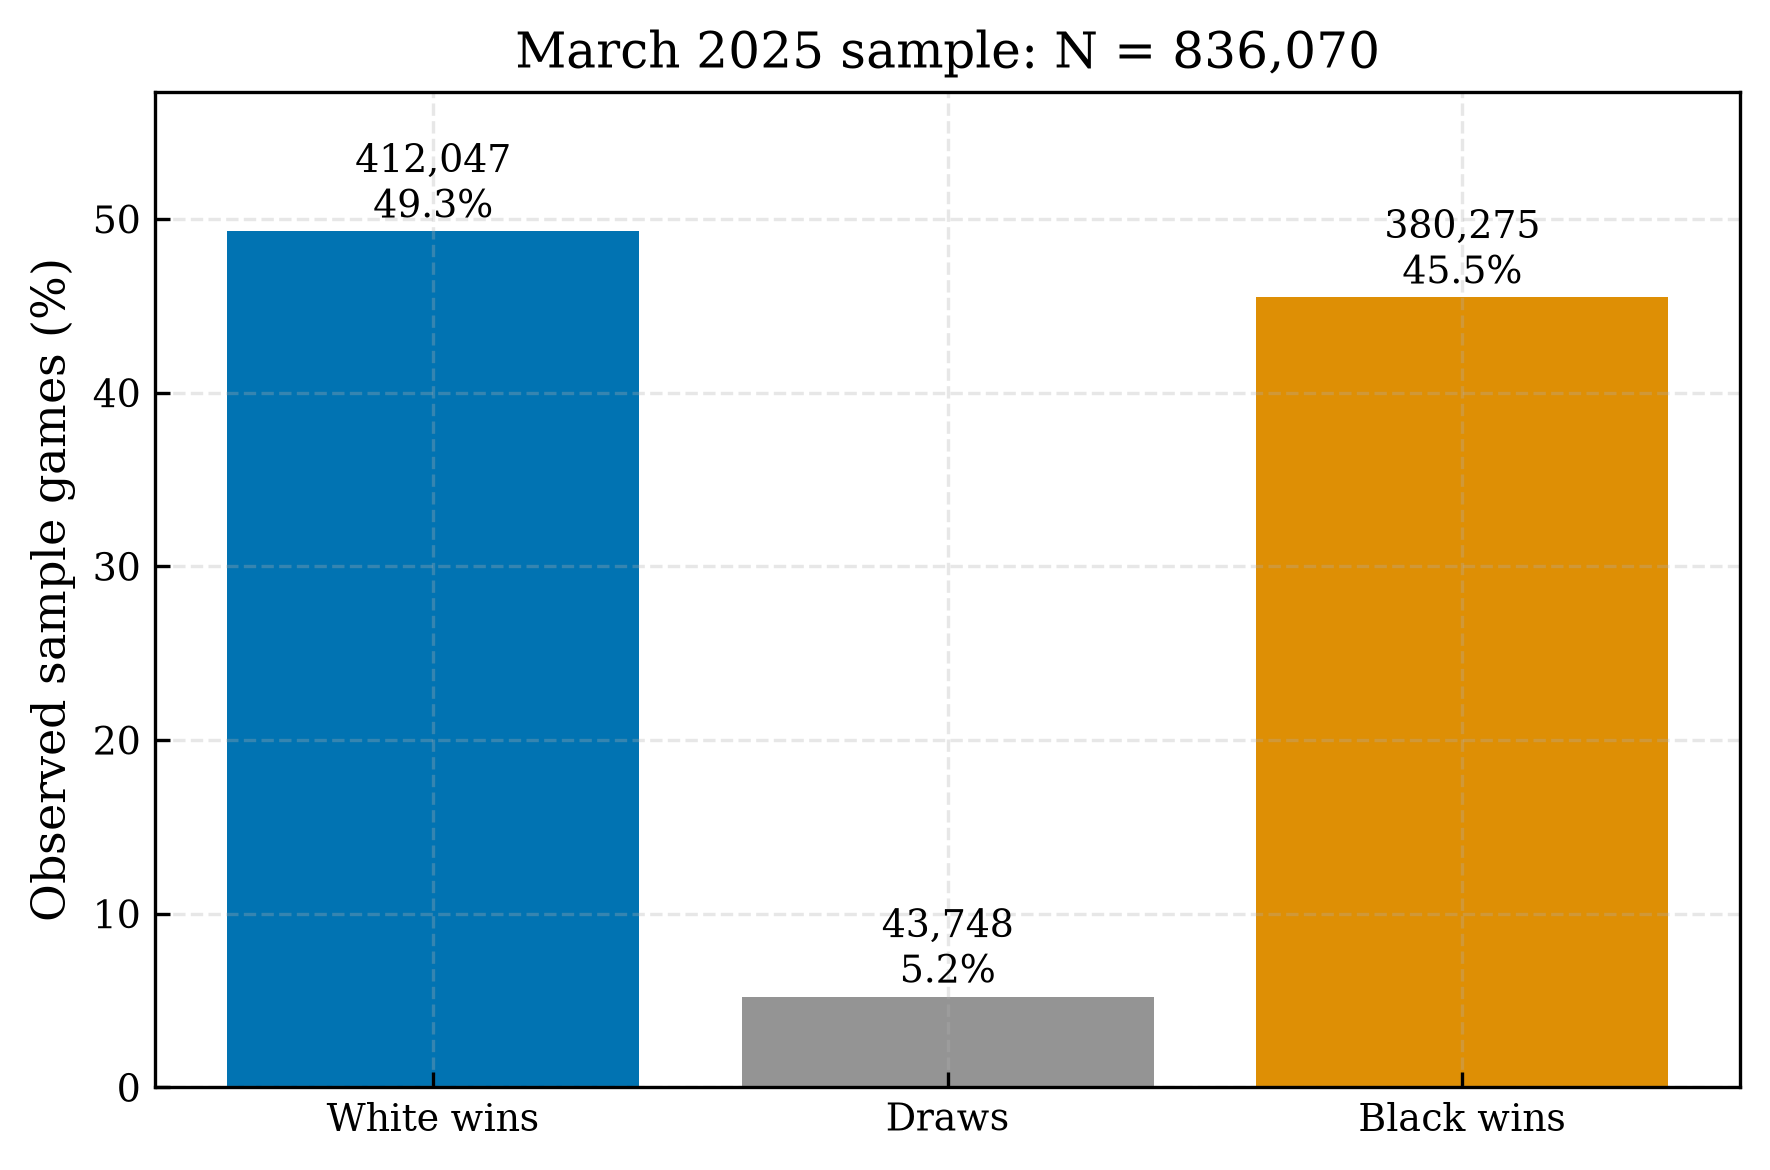

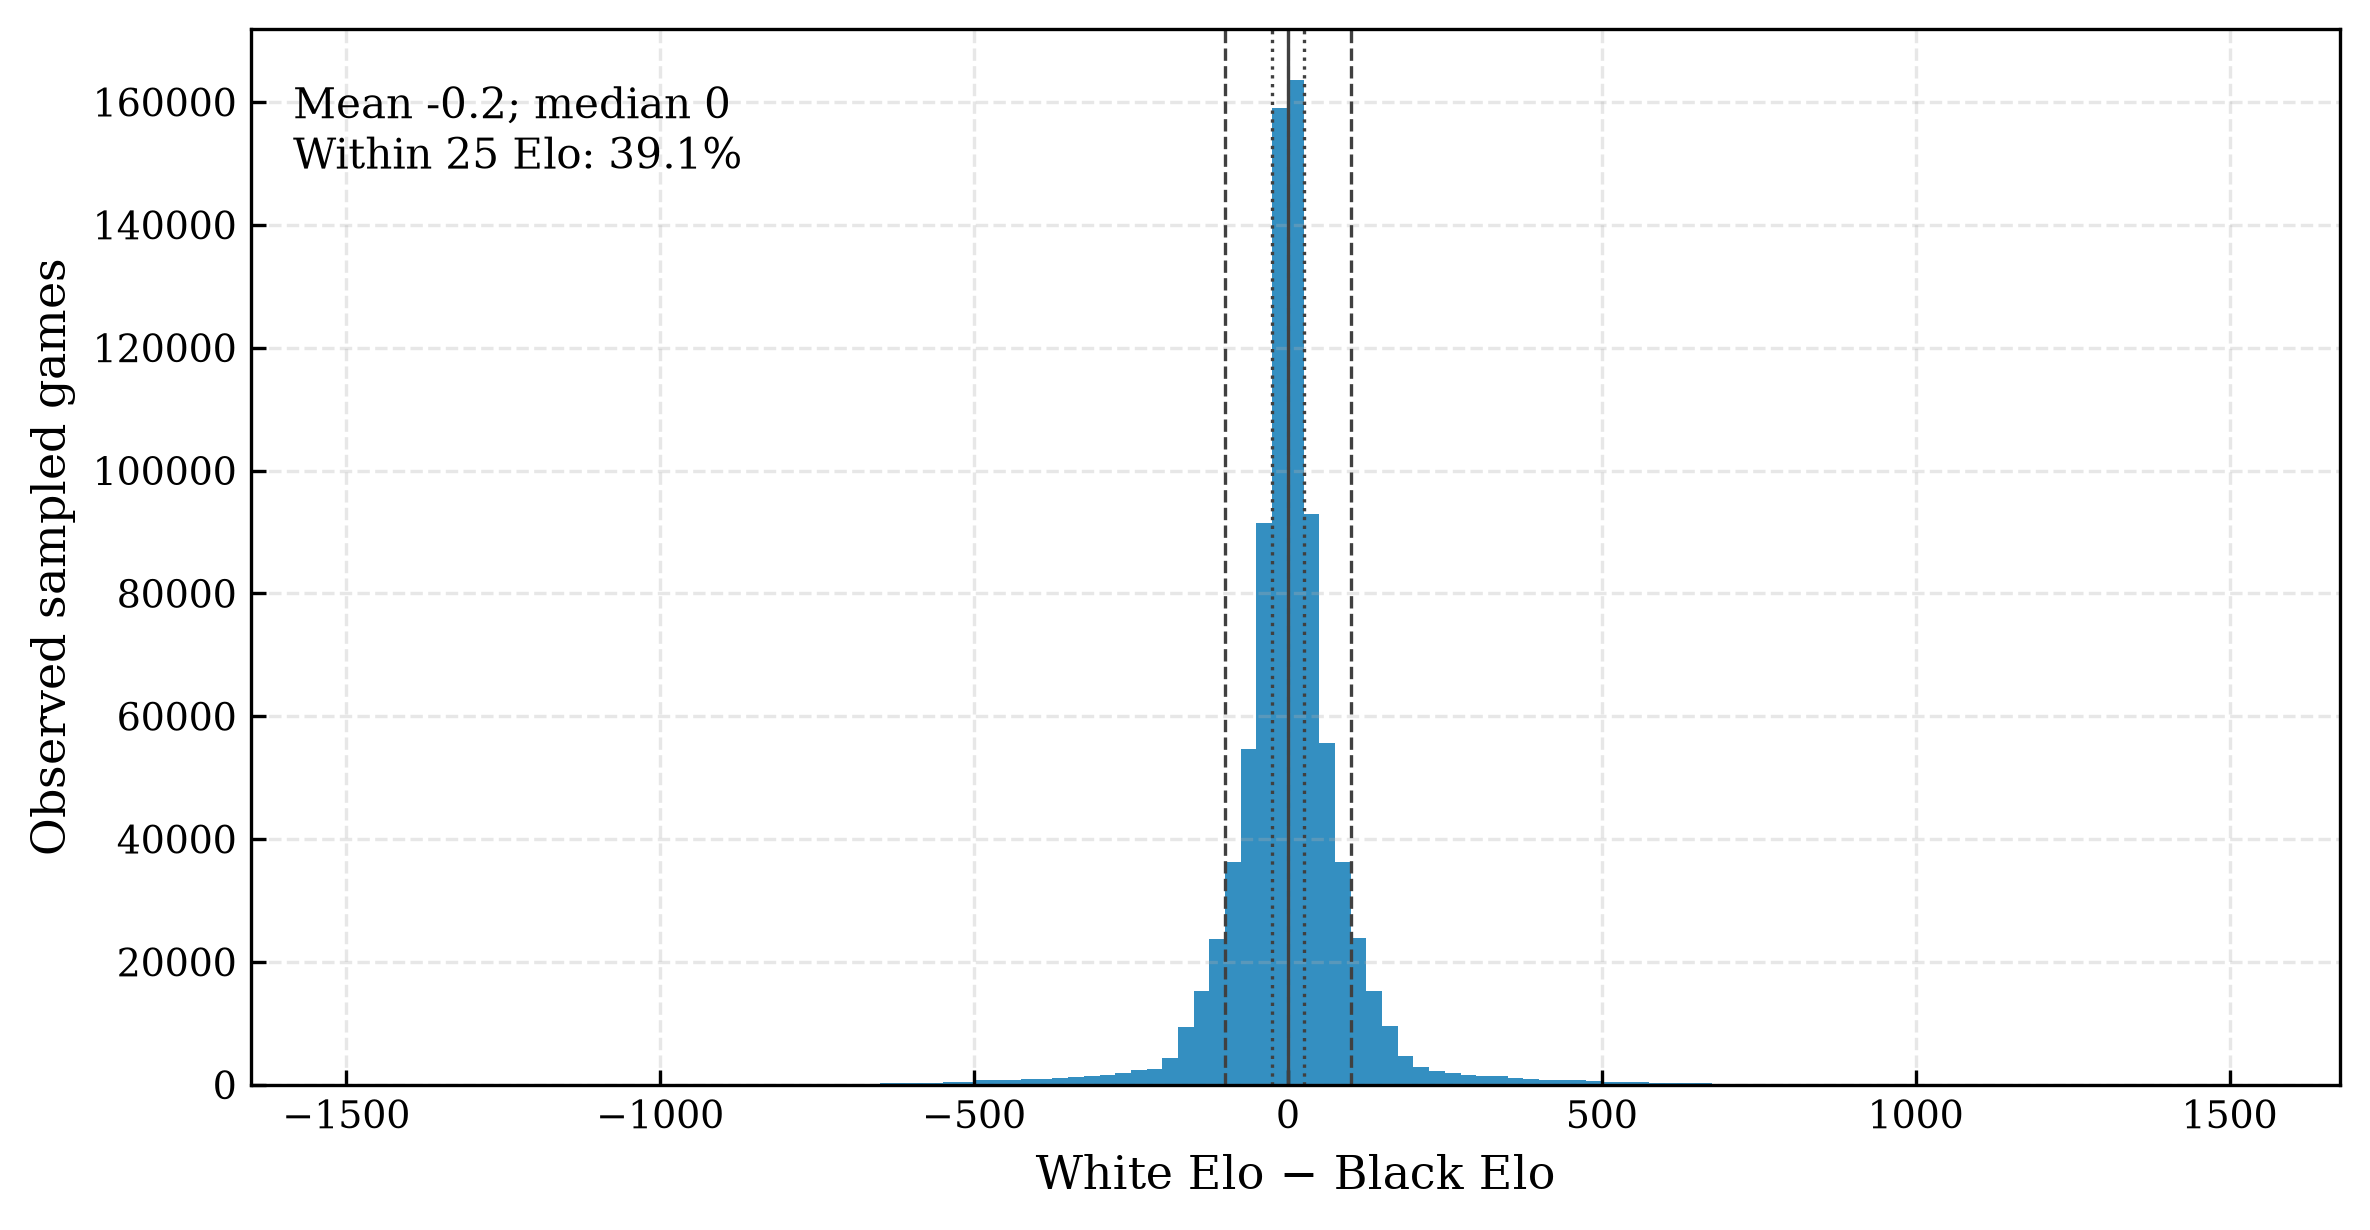

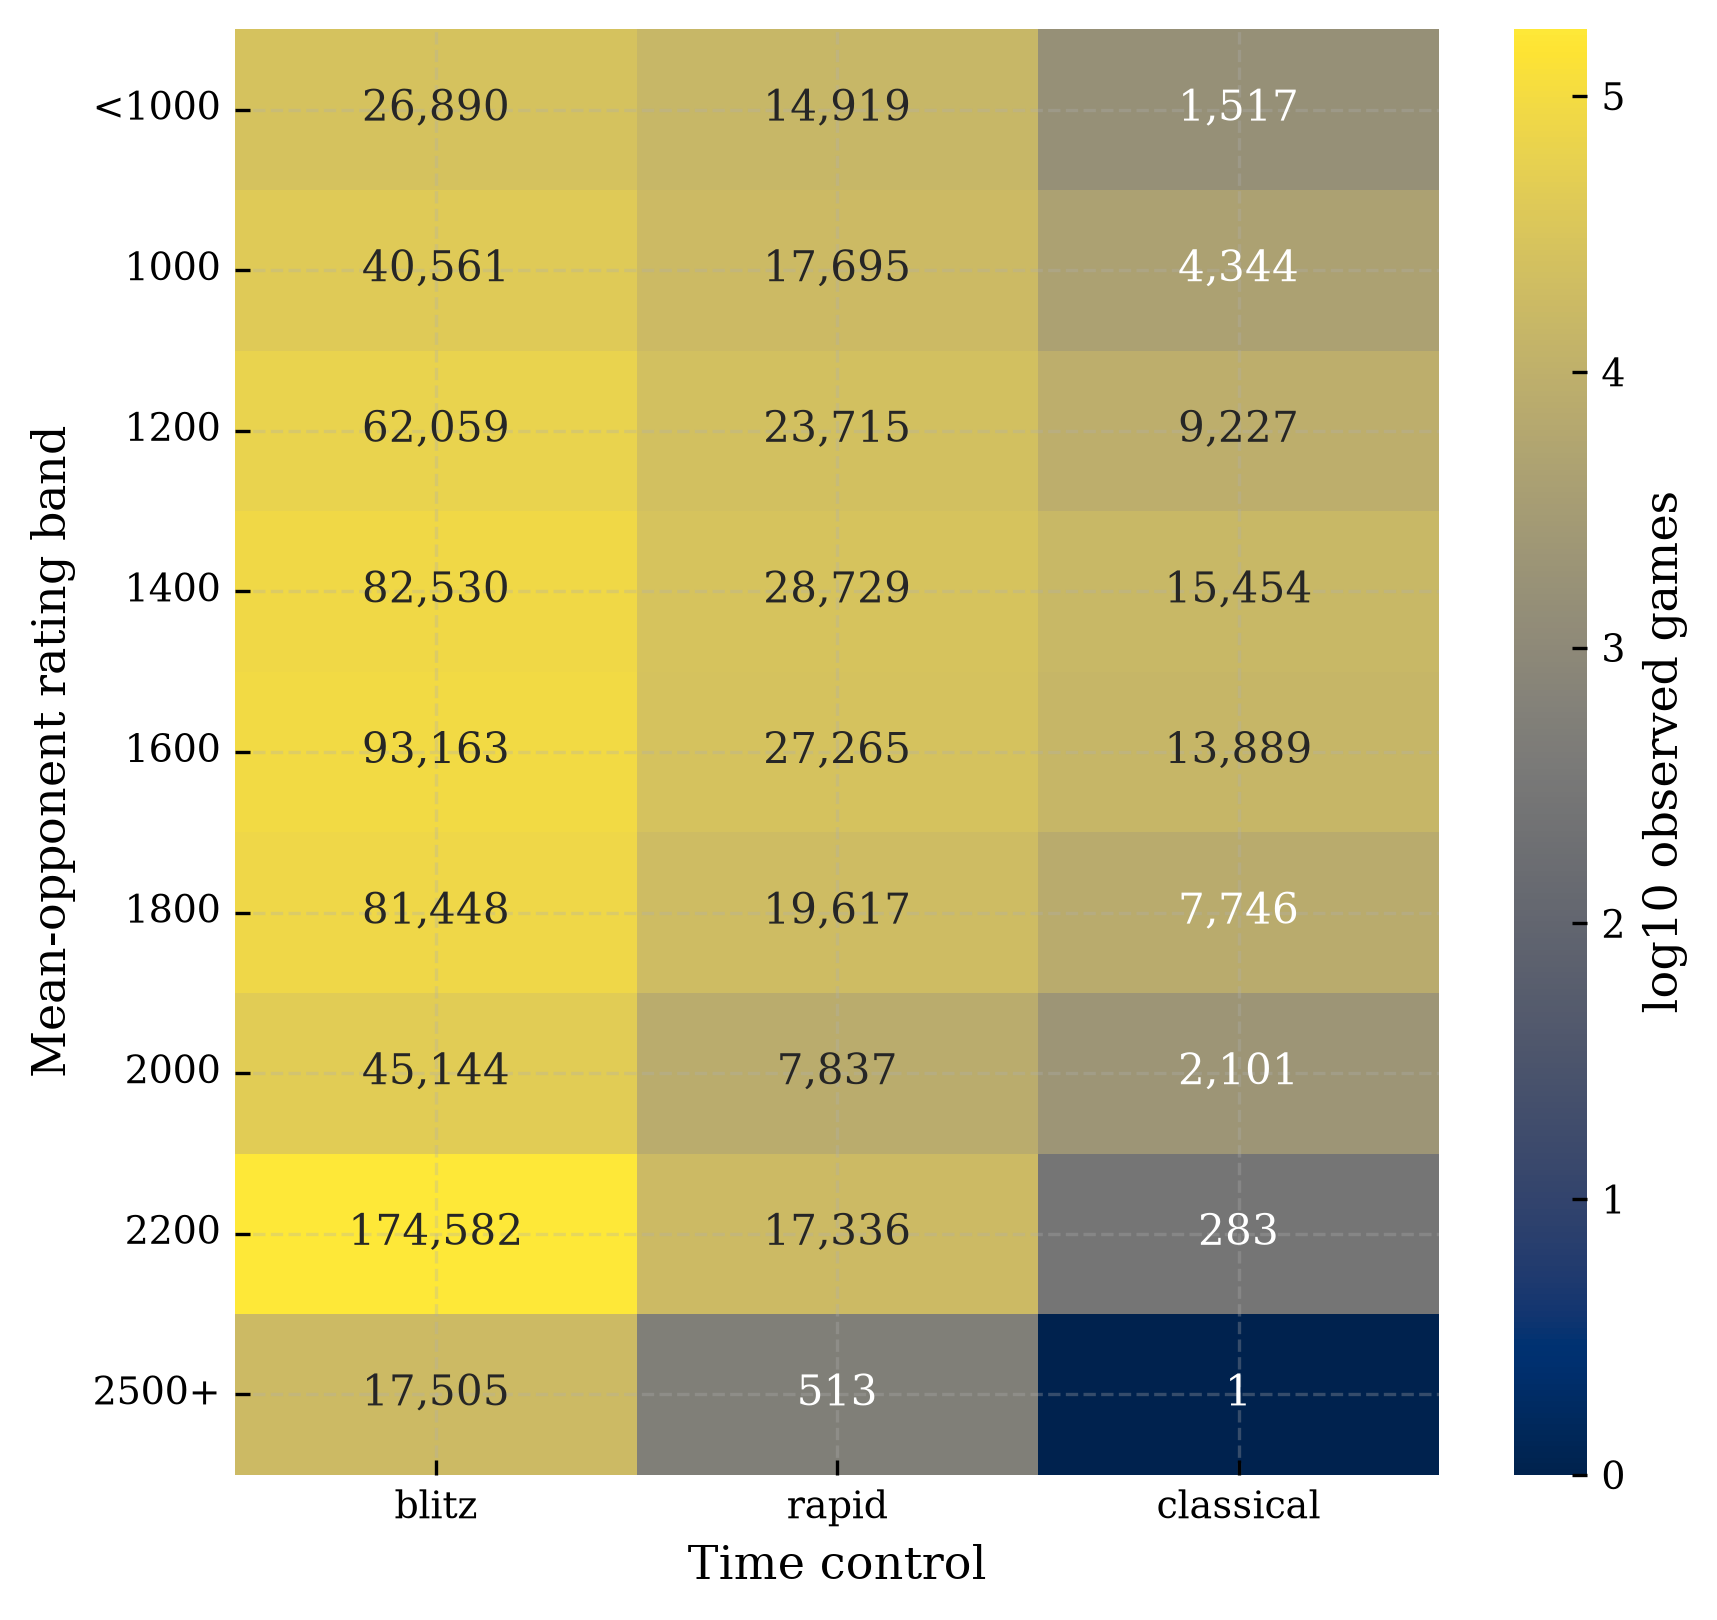

In [4]:
eda = table('eda_summary.csv')
display(eda)
display(table('opening_distribution.csv').head(12))
display(table('first_move_distribution.csv'))
display(table('black_reply_distribution.csv').head(15))
display(Markdown(f"Mean game length: **{dataset['mean_plies']:.2f} plies**; median **{dataset['median_plies']:.0f}**. There are **{dataset['unique_players']:,}** distinct player names and **{dataset['players_with_multiple_games']:,}** recurring players. Games are not interchangeable with independent players."))
for name in ['fig01_game_outcomes', 'fig05_rating_imbalance', 'fig06_sample_coverage']:
    figure(name)

## 6. White-score calculation

A White win is 1, draw 0.5 and Black win 0. Score S=(W+D/2)/N differs from White’s outright win probability W/N and decisive-game win rate W/(W+B). Empty/zero-decisive estimates are missing, not invented zeros. Pooled IPW score is sum(wY)/sum(w); estimated weighted totals do not determine the independent sample size.

In [5]:
display(pd.DataFrame([dataset['raw_metrics'], dataset['weighted_metrics']], index=['Observed sample', 'IPW population estimate']))
display(Markdown(f"Raw White score is **{100*raw['score']:.3f}%**; the weighted estimate is **{100*primary['score']:.3f}%**. Sampling correction changes the estimate by **{100*(primary['score']-raw['score']):+.3f} pp**. Weighted White win probability is **{100*primary['white_win_rate']:.3f}%**, so a score above half does not mean White wins more than half of all games."))

,N,weight_total,W,D,B,score,white_win_rate,draw_rate,black_win_rate,decisive_white_win_rate
Observed sample,836070,836070.00000,412047.00000,43748.00000,380275.00000,0.51900,0.49284,0.05233,0.45484,0.52005
IPW population estimate,836070,59802180.00000,29621880.00000,2682980.00000,27497320.00000,0.51776,0.49533,0.04486,0.45980,0.51860


Raw White score is **51.900%**; the weighted estimate is **51.776%**. Sampling correction changes the estimate by **-0.124 pp**. Weighted White win probability is **49.533%**, so a score above half does not mean White wins more than half of all games.

## 7. H1 statistical testing

The weighted ratio uses a Poisson multiplier bootstrap compressed by stratum/outcome, including random stratum masses and a Bernoulli finite-population correction sqrt(1-p). The model treats ID hashing as pseudo-random Bernoulli sampling. Intervals are percentile 95% intervals.

The null independently simulates W/D/B within each observed sampling cell with probabilities ((1-d)/2,d,(1-d)/2), preserving the draw probability. One-sided Monte Carlo p=(1+exceedances)/10001. The minimum possible p is 1/10001; a result at that floor must not be reported as zero. Exact conditional binomial tests validate decisive games for unweighted/equal-weight estimates only. Most intervals/tests initially assume independent outcomes; later sensitivities allow shared-player dependence.

,Group,N,White score,95% CI,Above 50% (pp),Adjusted p,Interpretation
0,Overall (primary weighted),"836,070",51.776%,51.653%–51.899%,+1.776,9.999e-05,Score above 50% detected


,N,score,lo,hi,se,difference_pp,weight_total,effective_n,white_wins,draws,...,status,omitted_sparse_rows,p_one_sided,model,standardization,covariance,rank,parameters,outside_unit_interval,unique_players
Raw sample,836070,0.51900,0.51794,0.52005,0.00054,1.90008,836070.00000,836070.00000,412047.00000,43748.00000,...,tested,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Within 25 Elo (IPW),327230,0.51819,0.51637,0.52004,0.00094,1.81853,26282420.00000,269426.57298,161803.00000,16289.00000,...,tested,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating standardized (dyadic),836069,0.51886,0.51707,0.52064,0.00091,NaN,NaN,NaN,NaN,NaN,...,NaN,1.00000,0.00000,IPW score mean regression: speed-band intercep...,"elo_difference=0, observed IPW speed-band comp...",dyadic shared-player sandwich,32.00000,32.00000,0.00000,NaN
Primary score (dyadic),836070,0.51776,0.51655,0.51898,0.00062,NaN,NaN,NaN,NaN,NaN,...,sensitivity,NaN,0.00000,NaN,NaN,NaN,NaN,NaN,NaN,567922.00000


White scores **51.776%** (95% CI **51.653–51.899%**), an excess of **1.776 pp**, with one-sided MC p=9.999e-05. Reject the primary 50% null under the stated design. The exact p=2.159e-279 applies to the **raw sample**, not the unequal-weight pooled estimate.

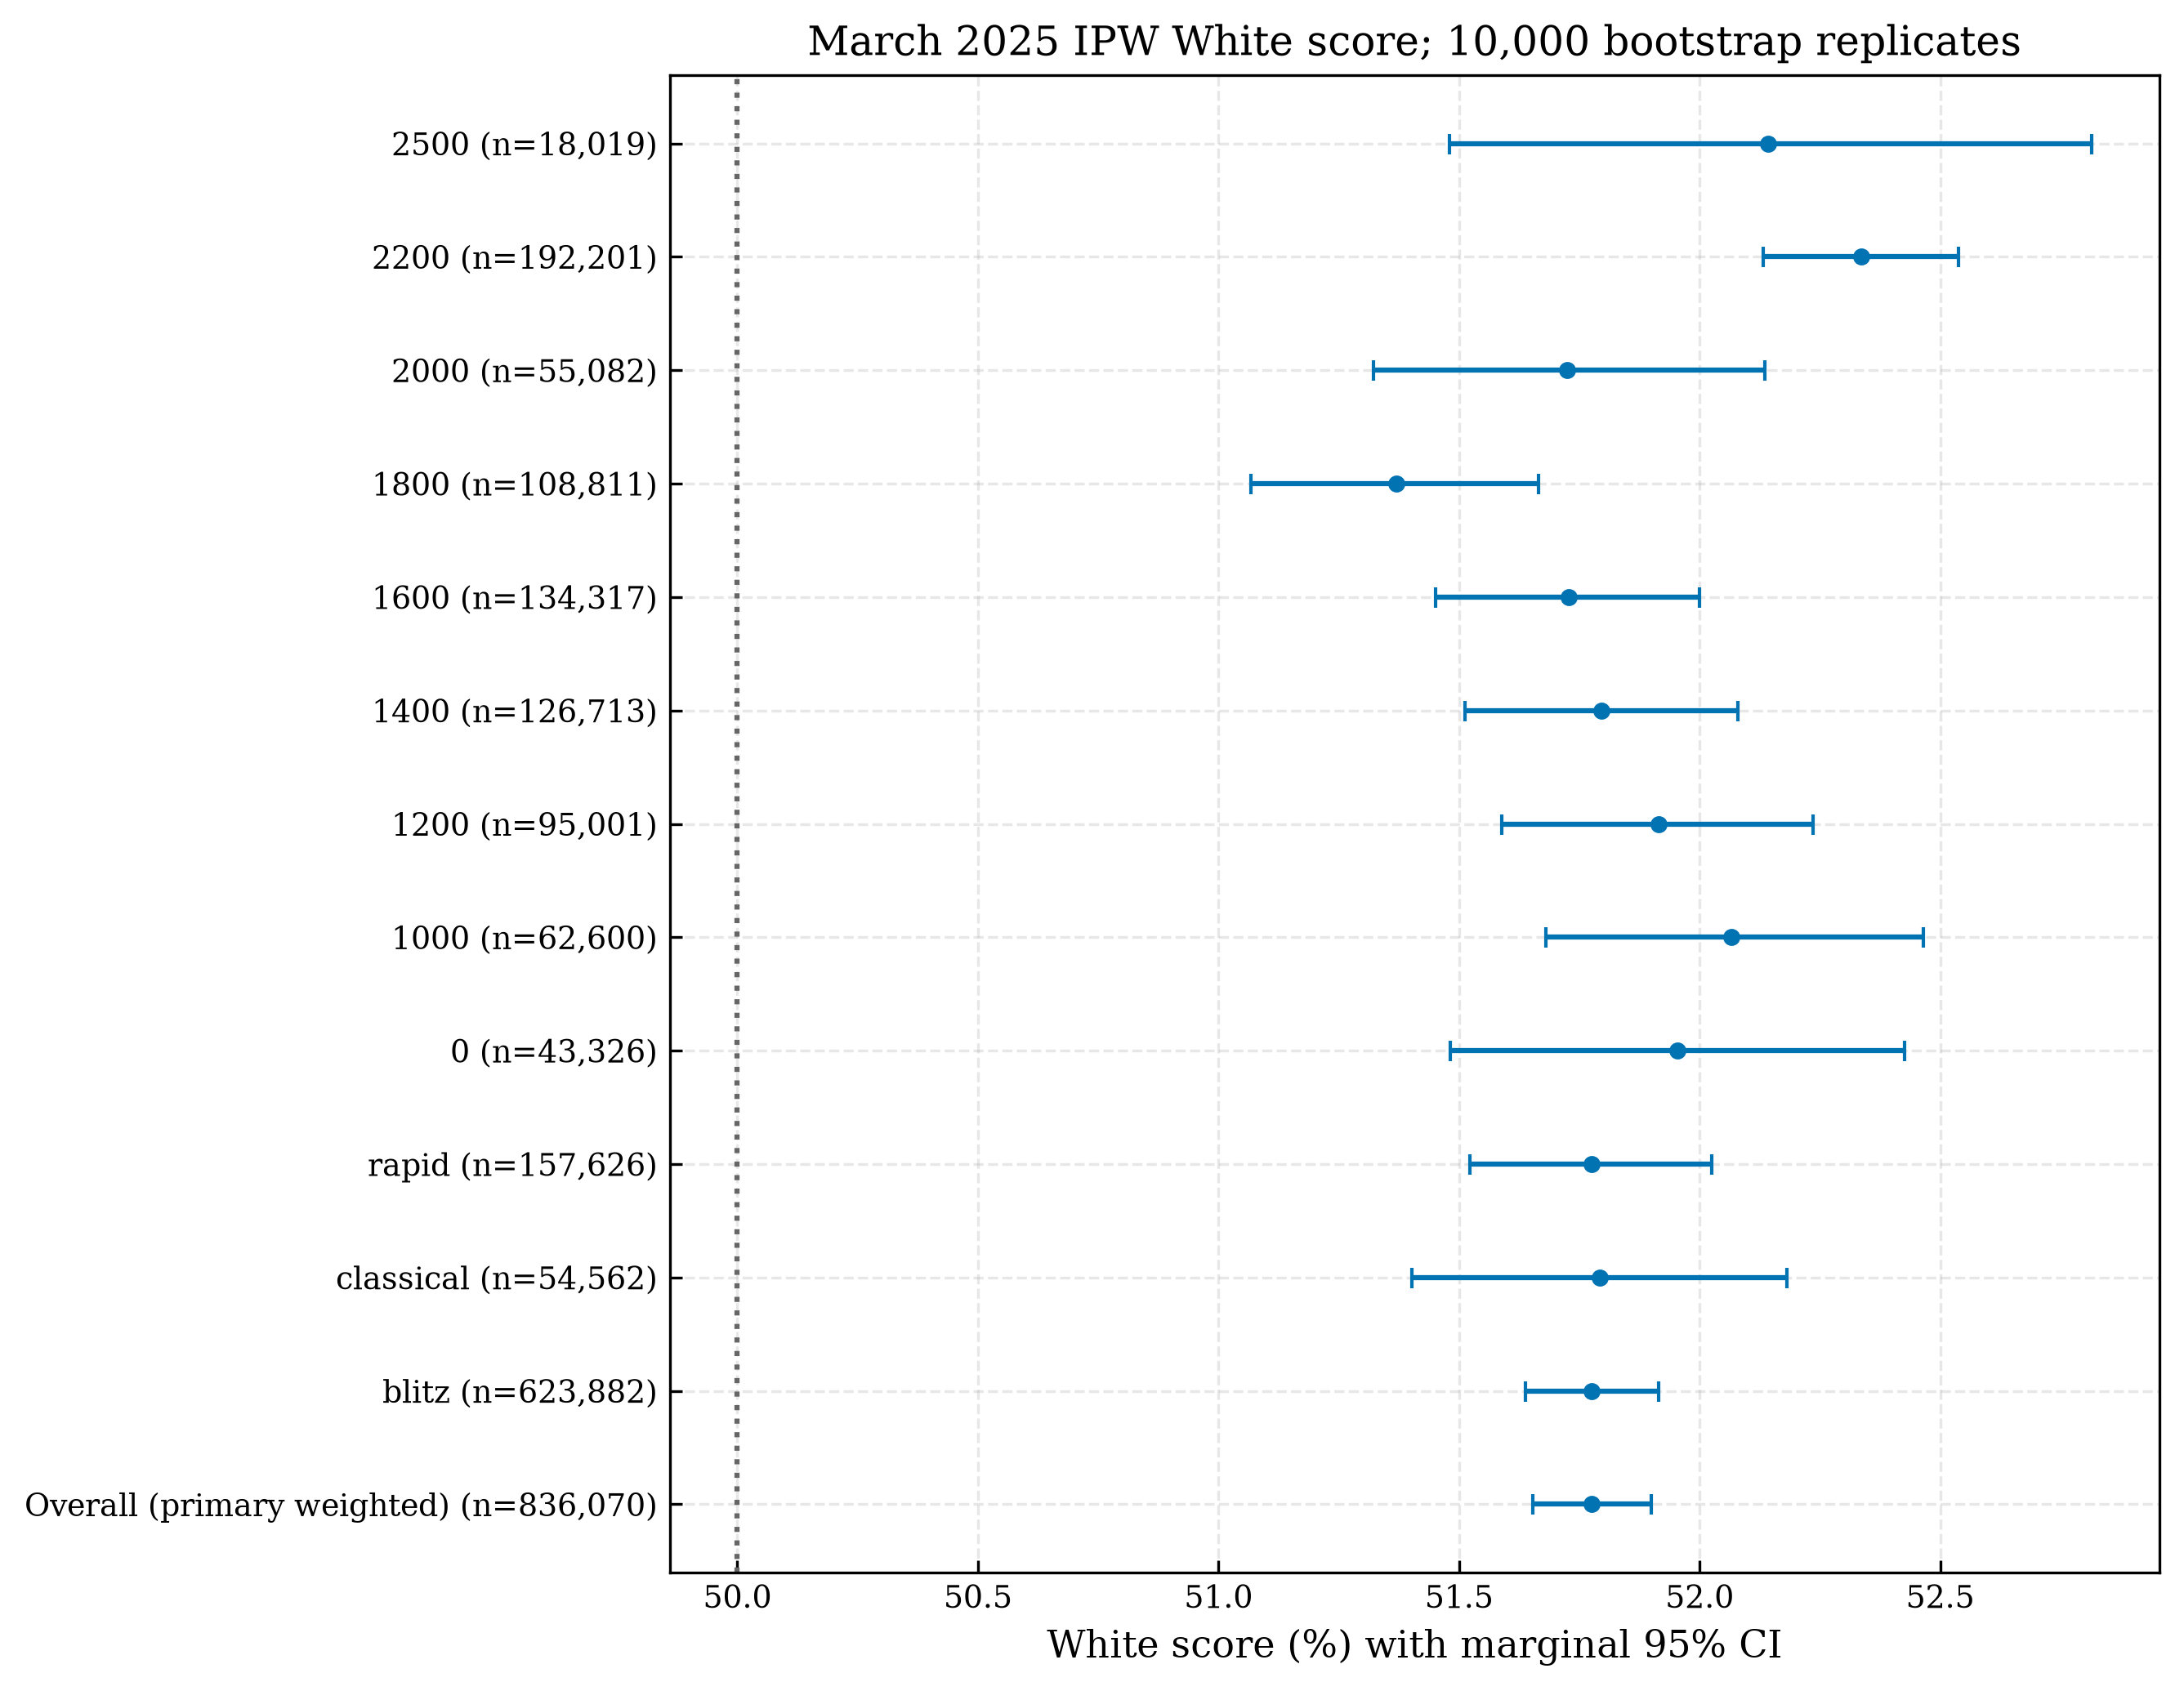

In [6]:
display(h1_display(h1[h1.group_type == 'primary']))
display(pd.DataFrame([raw, near, adjusted, s1['dyadic']], index=['Raw sample', 'Within 25 Elo (IPW)', 'Rating standardized (dyadic)', 'Primary score (dyadic)']))
display(Markdown(f"White scores **{100*primary['score']:.3f}%** (95% CI **{100*primary['lo']:.3f}–{100*primary['hi']:.3f}%**), an excess of **{primary['difference_pp']:.3f} pp**, with one-sided MC p={primary['p_mc']:.5g}. Reject the primary 50% null under the stated design. The exact p={raw['p_exact_unweighted']:.4g} applies to the **raw sample**, not the unequal-weight pooled estimate."))
figure('h1_score_confidence_intervals')

## 8. Rating and time-control comparisons

H1 secondary tests require n>=200 and >=20 decisive outcomes. One BH family covers eligible speed, band and speed-band tests, excluding the prespecified primary test. Marginal confidence intervals are not simultaneous. The rating-adjusted score model uses a natural cubic rating-difference spline and speed-band intercepts, then standardizes to Elo difference zero. It models the three-valued score mean directly without dropping draws.

,Group,N,White score,95% CI,Above 50% (pp),Adjusted p,Interpretation
1,blitz,"623,882",51.776%,51.637%–51.915%,+1.776,0.0001267,Score above 50% detected
2,classical,"54,562",51.793%,51.402%–52.182%,+1.793,0.0001267,Score above 50% detected
3,rapid,"157,626",51.776%,51.523%–52.024%,+1.776,0.0001267,Score above 50% detected
4,0,"43,326",51.954%,51.483%–52.425%,+1.954,0.0001267,Score above 50% detected
5,1000,"62,600",52.067%,51.680%–52.466%,+2.067,0.0001267,Score above 50% detected
6,1200,"95,001",51.914%,51.588%–52.235%,+1.914,0.0001267,Score above 50% detected
7,1400,"126,713",51.795%,51.512%–52.080%,+1.795,0.0001267,Score above 50% detected
8,1600,"134,317",51.727%,51.451%–51.999%,+1.727,0.0001267,Score above 50% detected
9,1800,"108,811",51.370%,51.067%–51.666%,+1.370,0.0001267,Score above 50% detected
10,2000,"55,082",51.725%,51.322%–52.136%,+1.725,0.0001267,Score above 50% detected


,Group,N,White score,95% CI,Above 50% (pp),Adjusted p,Interpretation
13,blitz/0,"26,890",51.913%,51.328%–52.504%,+1.913,0.0001267,Score above 50% detected
14,blitz/1000,"40,561",52.086%,51.613%–52.566%,+2.086,0.0001267,Score above 50% detected
15,blitz/1200,"62,059",51.931%,51.545%–52.317%,+1.931,0.0001267,Score above 50% detected
16,blitz/1400,"82,530",51.959%,51.623%–52.296%,+1.959,0.0001267,Score above 50% detected
17,blitz/1600,"93,163",51.633%,51.321%–51.952%,+1.633,0.0001267,Score above 50% detected
18,blitz/1800,"81,448",51.392%,51.055%–51.728%,+1.392,0.0001267,Score above 50% detected
19,blitz/2000,"45,144",51.647%,51.202%–52.102%,+1.647,0.0001267,Score above 50% detected
20,blitz/2200,"174,582",52.276%,52.063%–52.489%,+2.276,0.0001267,Score above 50% detected
21,blitz/2500,"17,505",52.234%,51.562%–52.922%,+2.234,0.0001267,Score above 50% detected
22,classical/0,"1,517",52.966%,50.630%–55.231%,+2.966,0.008793,Score above 50% detected


The near-equal score is **51.819%**, and the equal-rating standardized score is **51.886%** (dyadic CI **51.707–52.064%**). The direction remains positive. Band scores are not monotonic in strength; pooled speed scores are similar, which does not prove equivalence. Sparse high-rated classical cells are inconclusive.

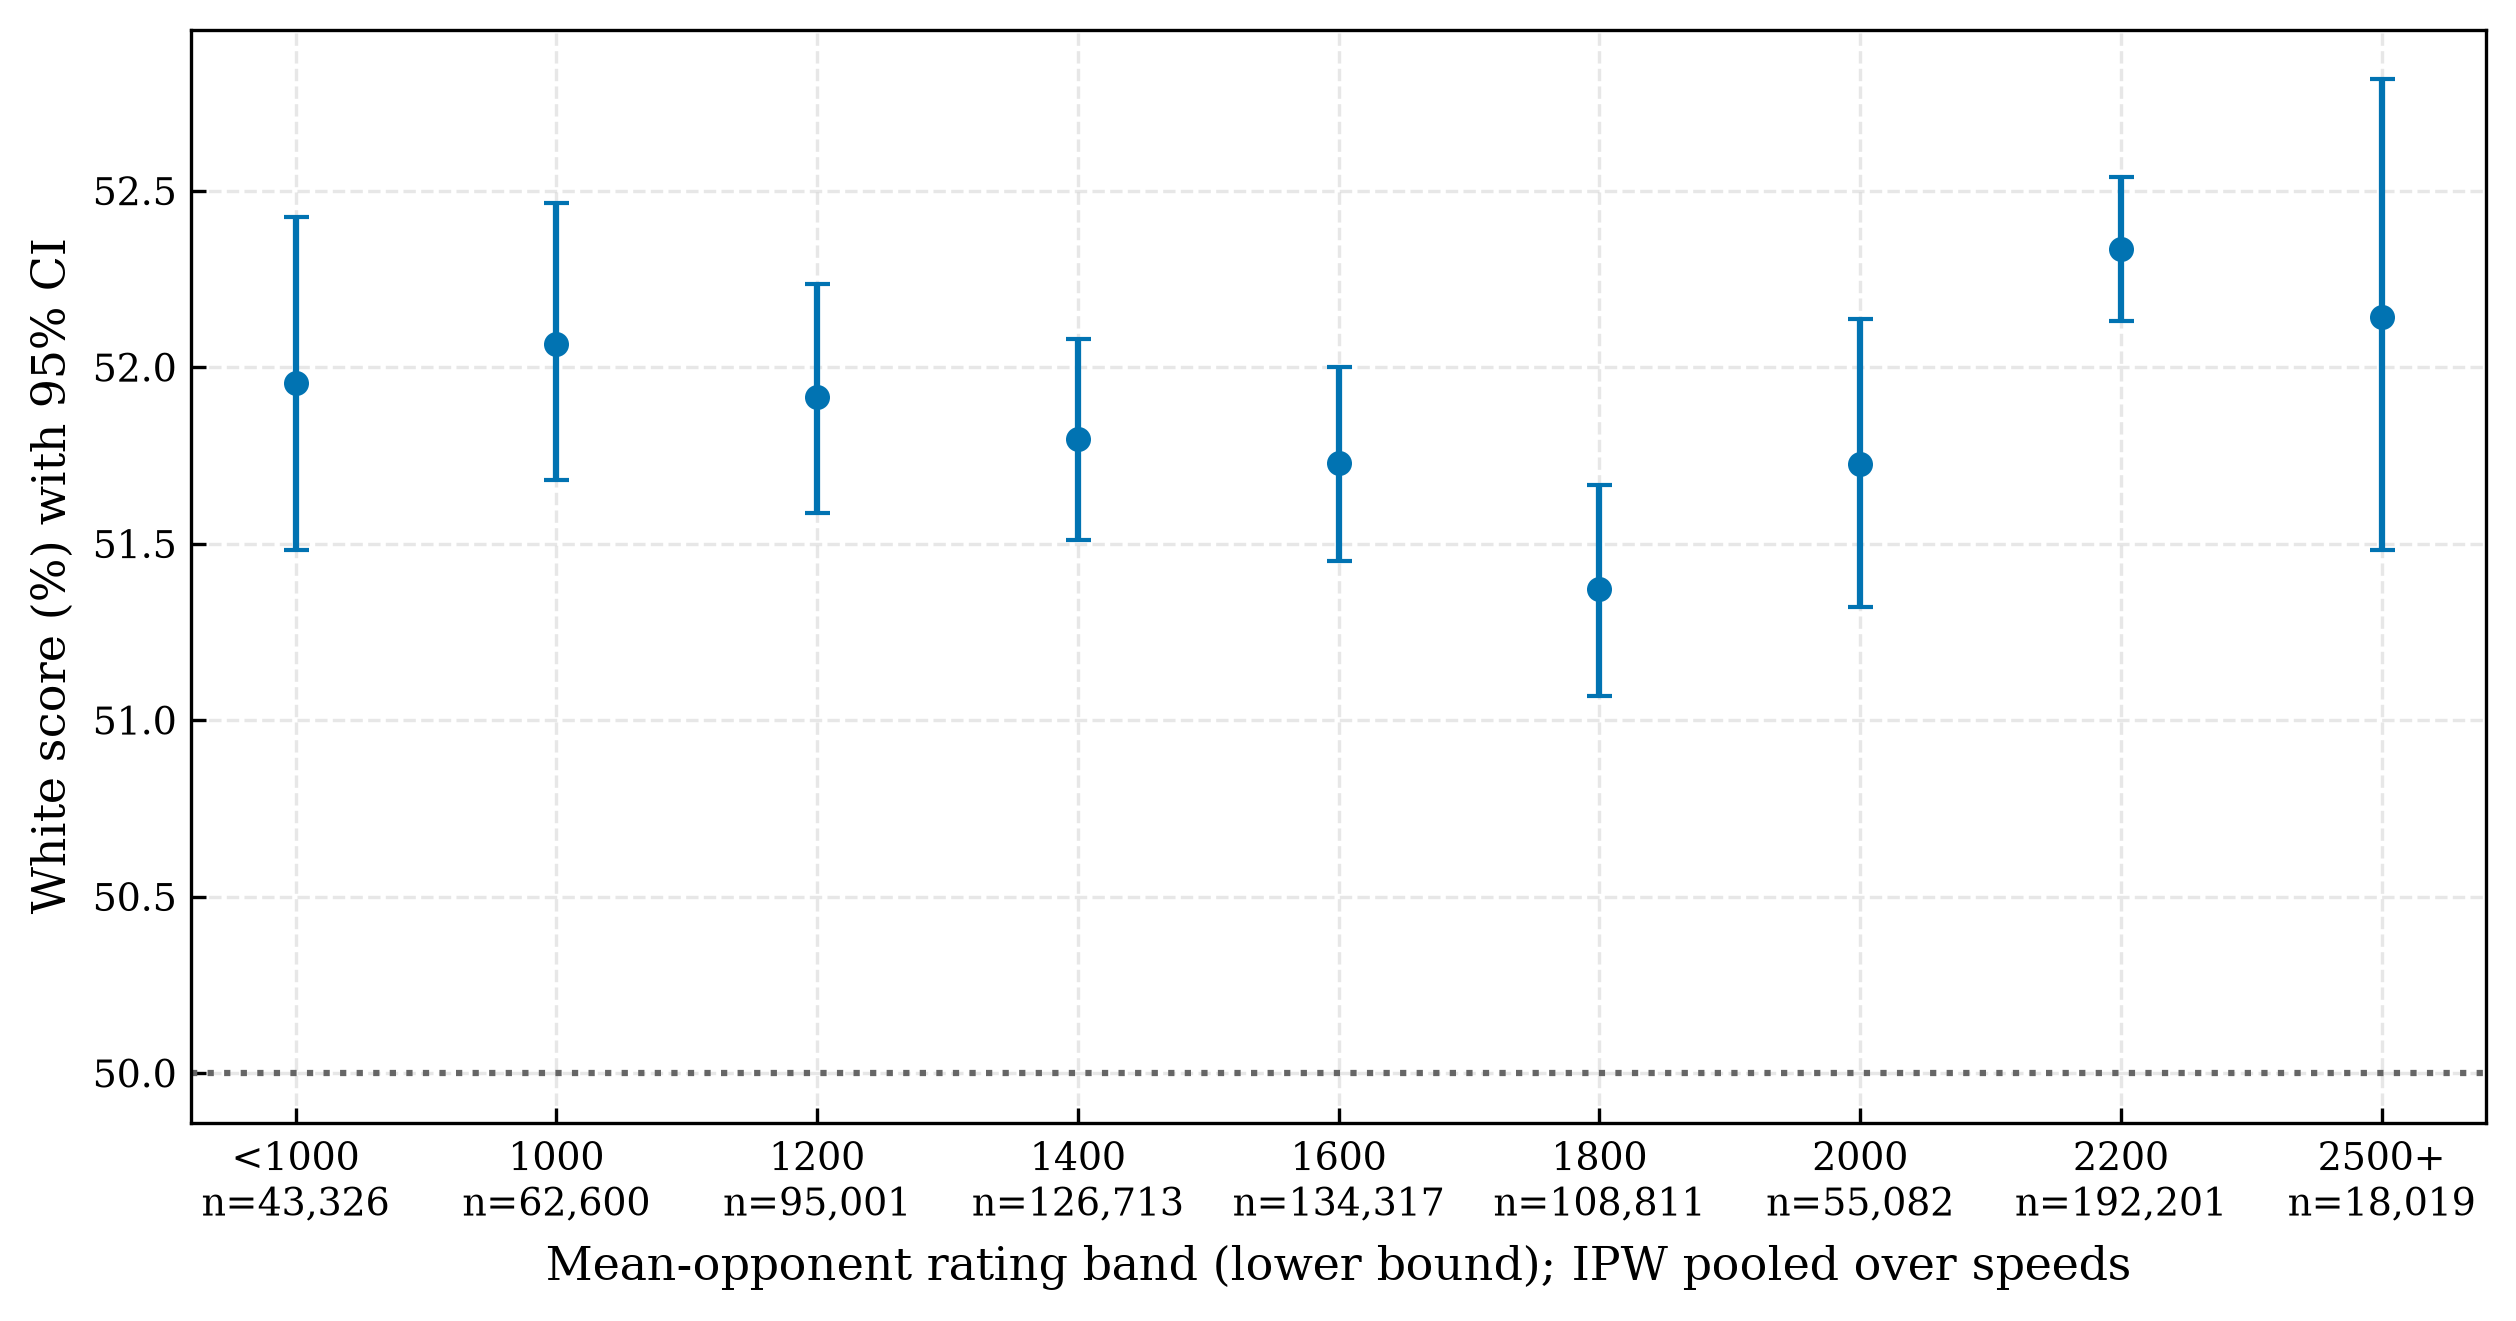

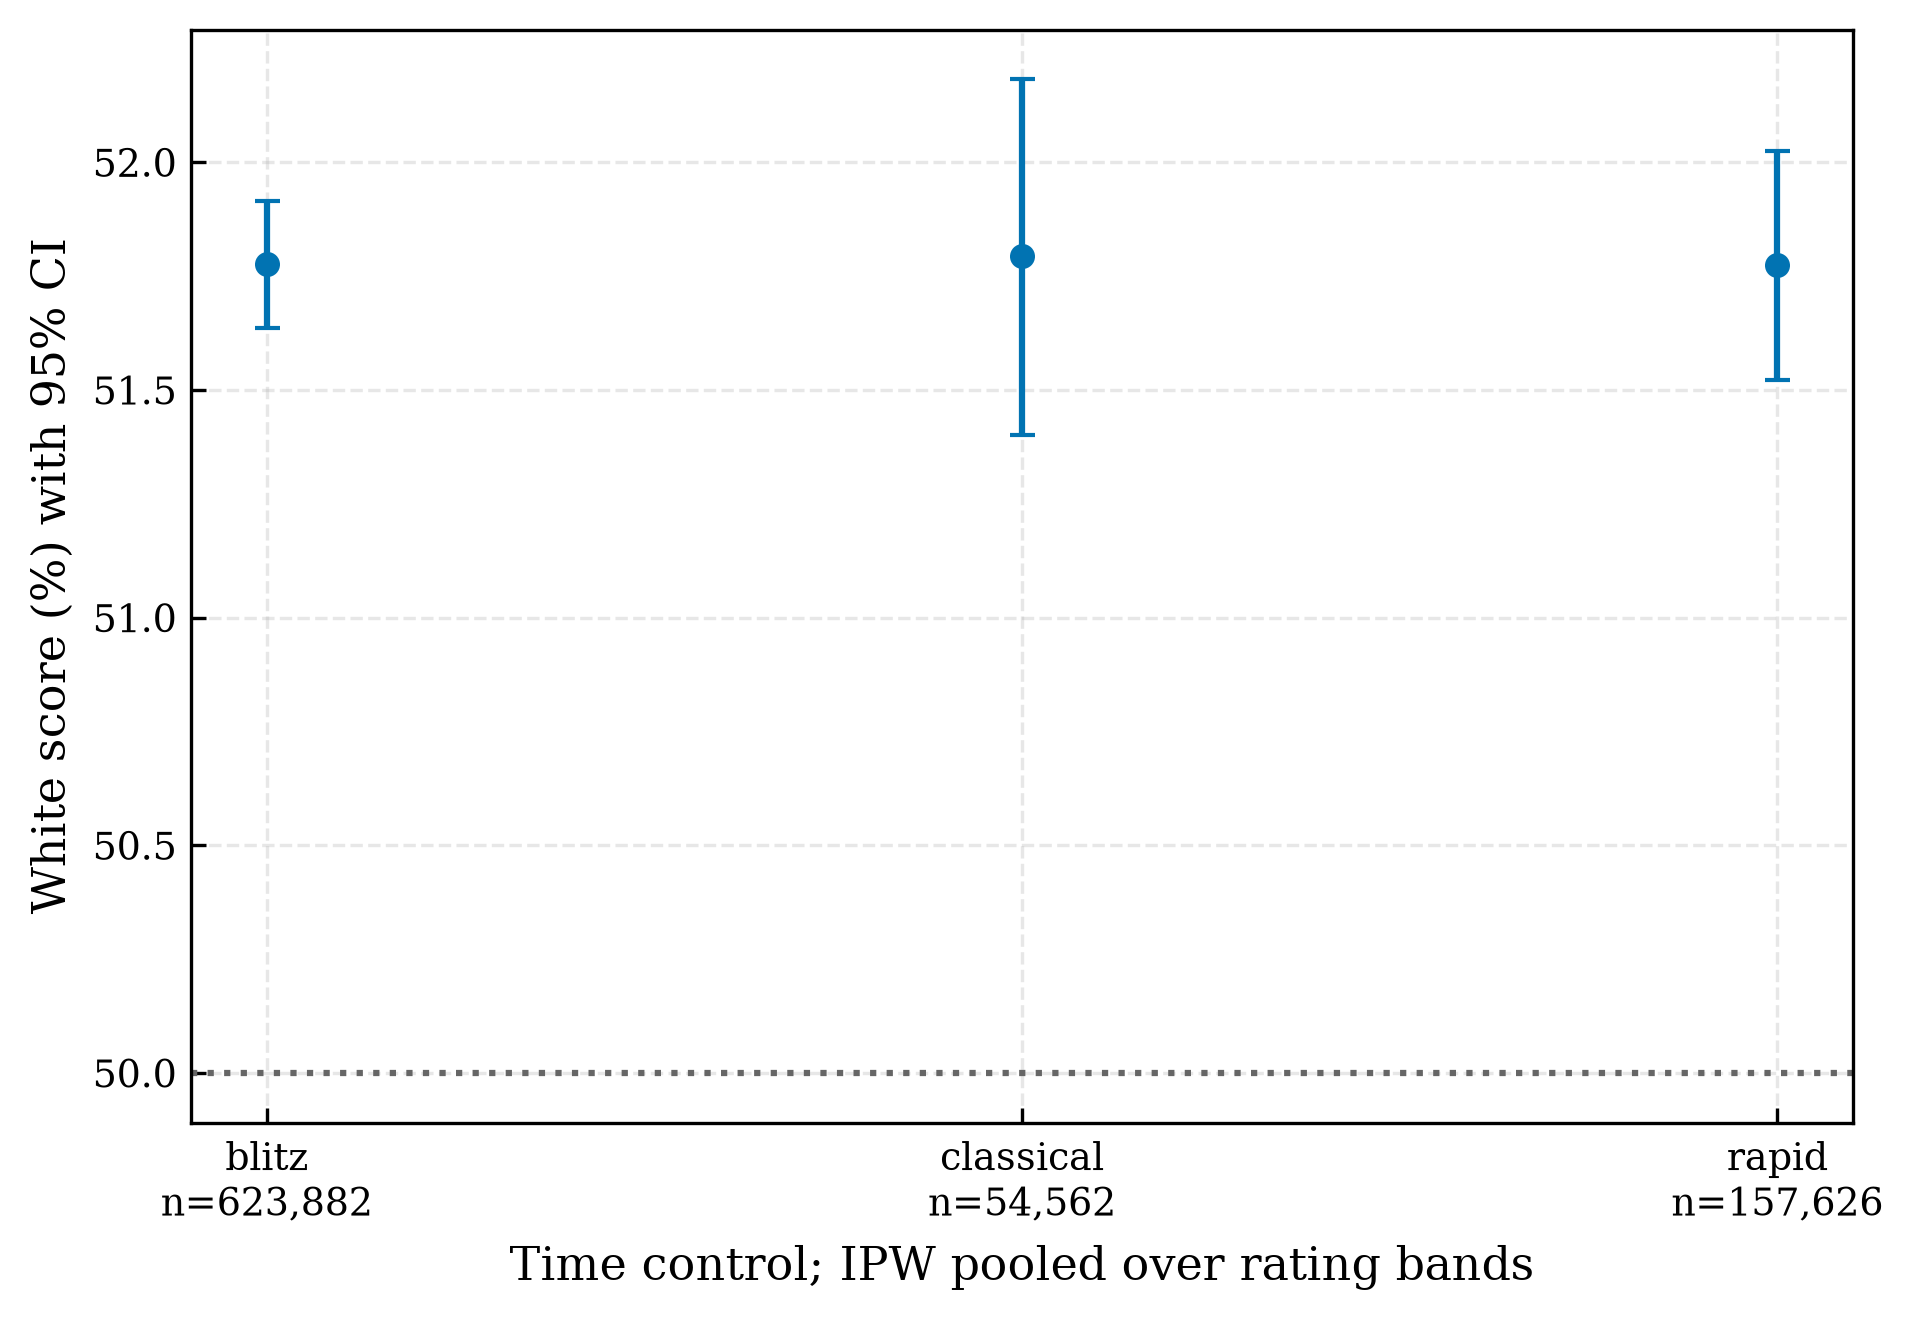

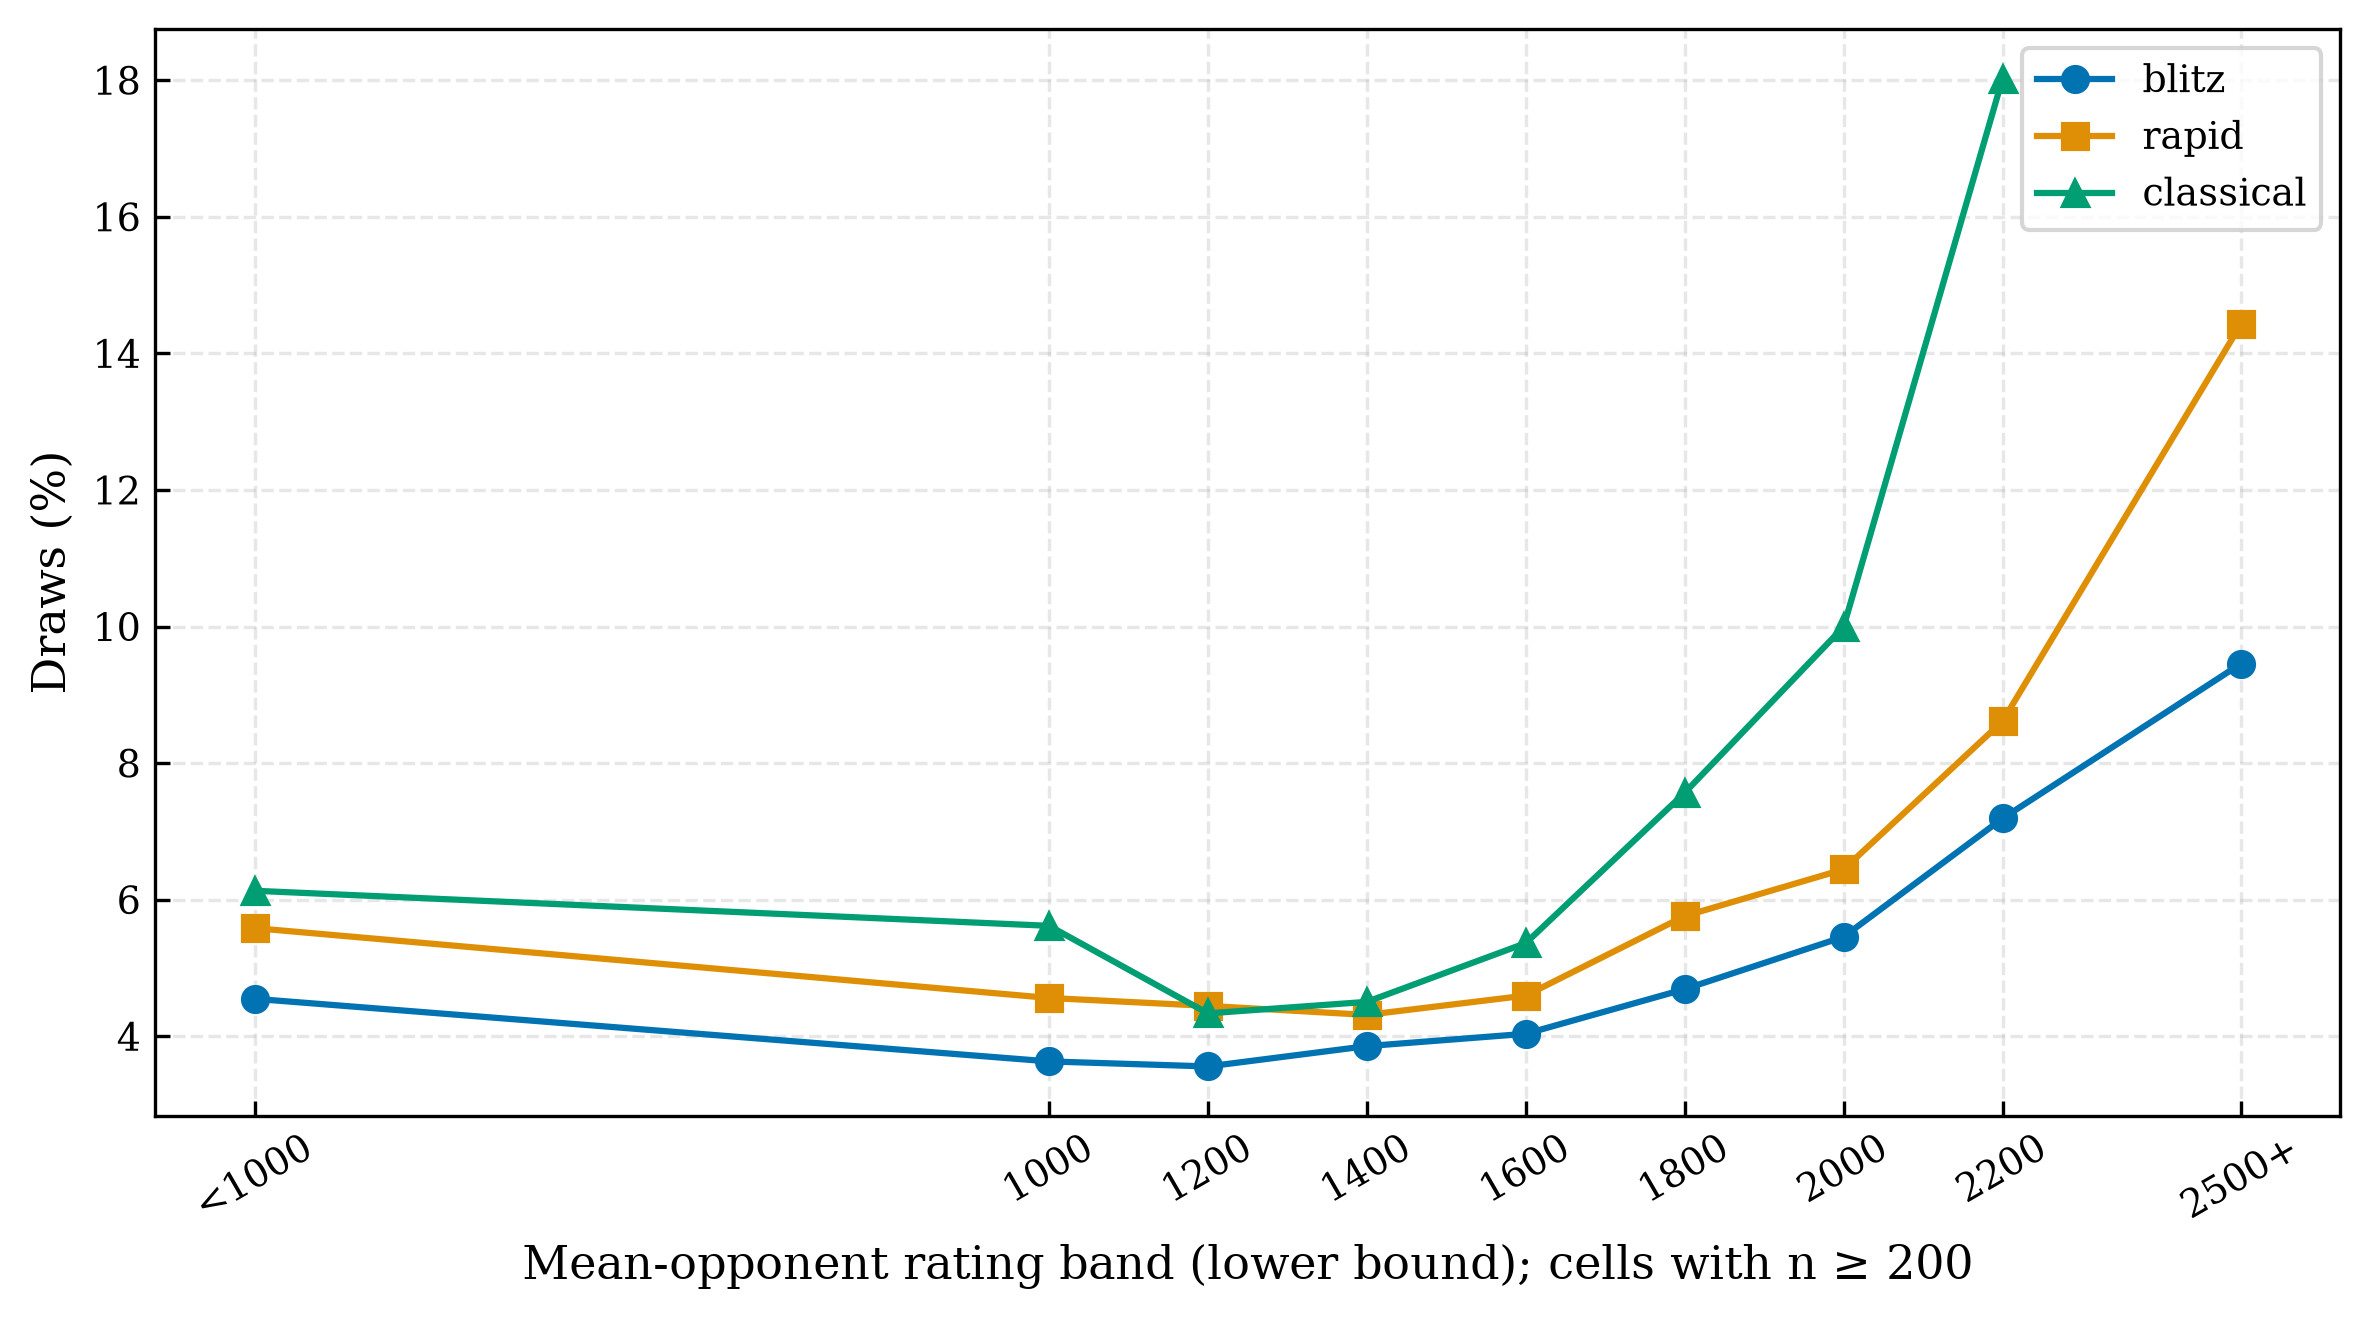

In [7]:
display(h1_display(h1[h1.group_type.isin(['speed', 'band'])]))
display(h1_display(h1[h1.group_type == 'cell']))
display(Markdown(f"The near-equal score is **{100*near['score']:.3f}%**, and the equal-rating standardized score is **{100*adjusted['score']:.3f}%** (dyadic CI **{100*adjusted['lo']:.3f}–{100*adjusted['hi']:.3f}%**). The direction remains positive. Band scores are not monotonic in strength; pooled speed scores are similar, which does not prove equivalence. Sparse high-rated classical cells are inconclusive."))
for name in ['fig02_score_by_band', 'fig03_score_by_speed', 'fig04_draw_rate_by_band']:
    figure(name)

## 9. H2: Black’s first reply

Each e4/d4 game enters exactly one immediate-reply group. Primary March floor: 200 observed games/reply, band>=1200, and at least two eligible replies/cell; the optional Explorer floor remains 10,000. The score statistic is the n-weighted SD of reply scores; the full-distribution Pearson statistic can also detect draw-only changes. Both use 10,000 multinomial null tables and separate BH families across eligible cells.

Reported range is max−min score; excess SD removes expected squared sampling noise descriptively. Reply intervals are marginal bootstrap intervals (conservative exact bounds for sparse/constant samples). Comparisons against the remaining eligible replies use disjoint groups. Selected extremes are descriptive; they do not establish an objectively best defense.

,First,Speed,Band,Included N,Replies,Coverage,Range (pp),Excess SD (pp),q score,q W/D/B,Highest White score,Lowest White score
2,d4,blitz,1200,13856,10,98.1%,7.18,1.80,0.005444,0.03069,d5,f5
3,d4,blitz,1400,19261,10,98.4%,4.82,0.96,0.1137,0.008749,d5,c5
4,d4,blitz,1600,23164,10,98.7%,6.24,1.00,0.06416,0.03375,e6,c5
5,d4,blitz,1800,21856,10,98.6%,3.64,0.60,0.2951,0.7327,e5,c5
6,d4,blitz,2000,13051,9,97.3%,5.27,1.10,0.1138,0.0497,e6,c5
7,d4,blitz,2200,56097,11,99.3%,5.02,0.24,0.4151,0.001312,b6,d6
8,d4,blitz,2500,5188,4,88.9%,2.97,0.00,0.7587,0.3252,e6,d5
12,d4,classical,1400,2480,3,78.1%,7.62,2.49,0.0335,0.06539,d5,Nf6
13,d4,classical,1600,2611,3,80.7%,8.49,3.13,0.007349,0.03069,d5,e6
14,d4,classical,1800,1522,2,75.7%,2.86,0.66,0.3466,0.5955,d5,Nf6


,first,speed,band,reply,W,D,B,N,draw_rate,eligible,tested,score,lo,hi,se,rest_score,difference_from_rest_pp,difference_rest_lo_pp,difference_rest_hi_pp
80,d4,blitz,1600,Nf6,2079,169,1894,4142,0.04080,True,True,0.52233,0.50736,0.53718,0.00758,0.52534,-0.30069,-1.94047,1.33910
84,d4,blitz,1600,b6,255,22,274,551,0.03993,True,True,0.48276,0.44192,0.52359,0.02084,0.52583,-4.30672,-8.44111,-0.17234
85,d4,blitz,1600,c5,383,35,412,830,0.04217,True,True,0.48253,0.44940,0.51506,0.01691,0.52637,-4.38422,-7.75932,-1.00912
86,d4,blitz,1600,c6,481,45,432,958,0.04697,True,True,0.52557,0.49478,0.55637,0.01566,0.52477,0.08060,-3.05548,3.21669
87,d4,blitz,1600,d5,5254,484,4618,10356,0.04674,True,True,0.53071,0.52149,0.54007,0.00477,0.52003,1.06803,-0.19426,2.33032
88,d4,blitz,1600,d6,369,34,371,774,0.04393,True,True,0.49871,0.46447,0.53295,0.01764,0.52570,-2.69954,-6.21557,0.81648
89,d4,blitz,1600,e5,763,51,714,1528,0.03338,True,True,0.51603,0.49182,0.54090,0.01254,0.52542,-0.93866,-3.48031,1.60300
90,d4,blitz,1600,e6,1222,90,1013,2325,0.03871,True,True,0.54495,0.52516,0.56430,0.01006,0.52255,2.23924,0.15917,4.31930
91,d4,blitz,1600,f5,257,17,230,504,0.03373,True,True,0.52679,0.48413,0.56944,0.02189,0.52476,0.20284,-4.13518,4.54087
94,d4,blitz,1600,g6,602,36,558,1196,0.03010,True,True,0.51839,0.49080,0.54600,0.01427,0.52515,-0.67556,-3.54522,2.19411


Tested replies cover **84.3%** of all e4/d4 games and **96.9%** within eligible bands. **14/35** score-spread tests and **15/35** full-distribution tests reject after their separate BH corrections. Median range: **6.24 pp**; median excess SD: **1.20 pp**. Evidence concerns some cells, not all replies in all populations.

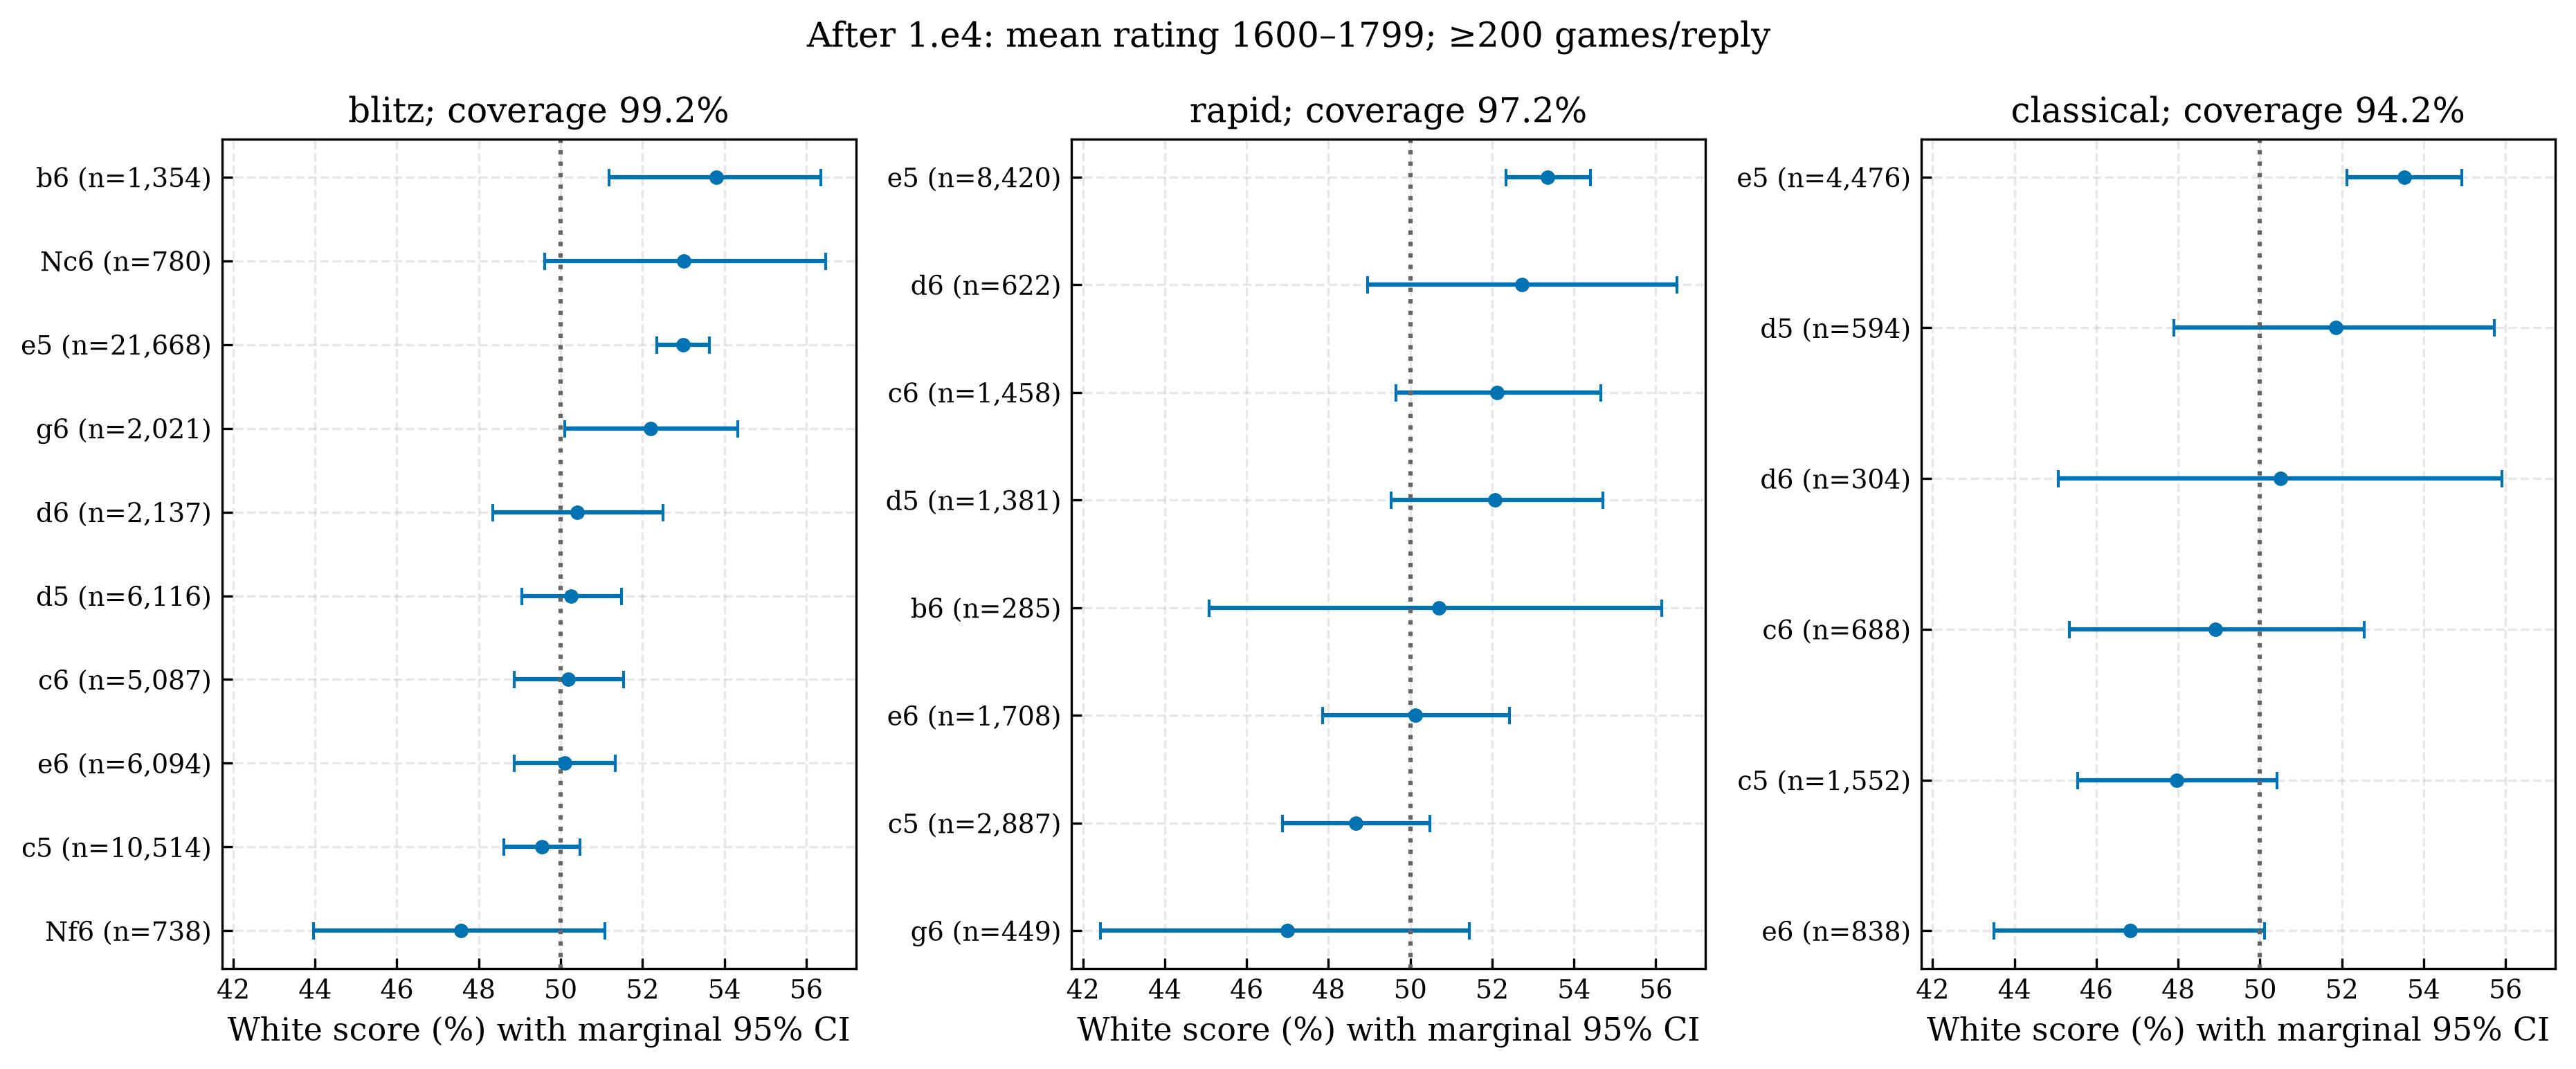

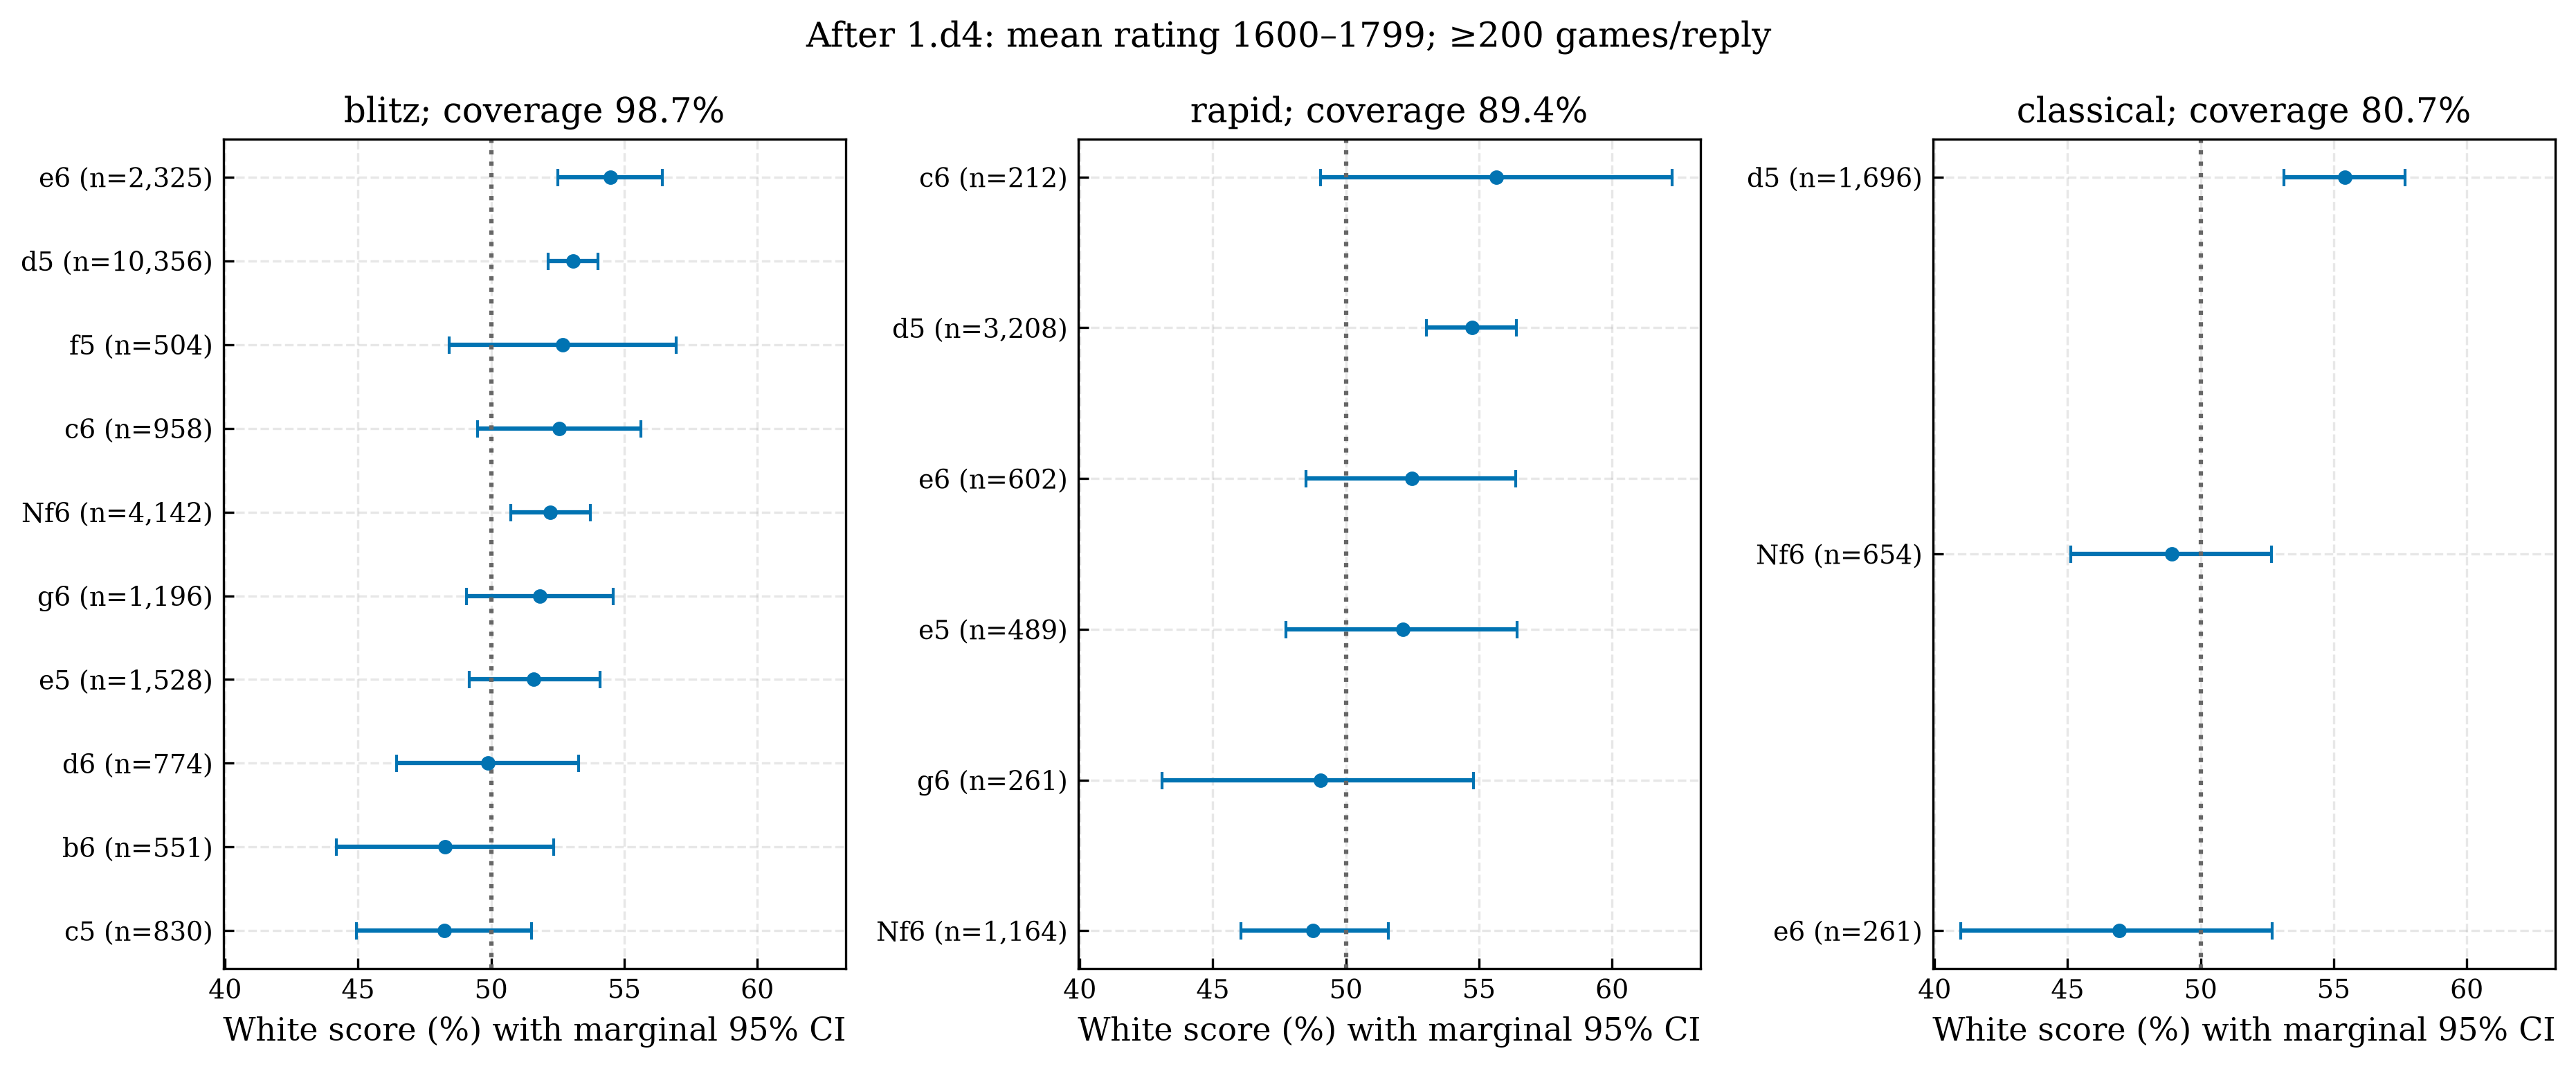

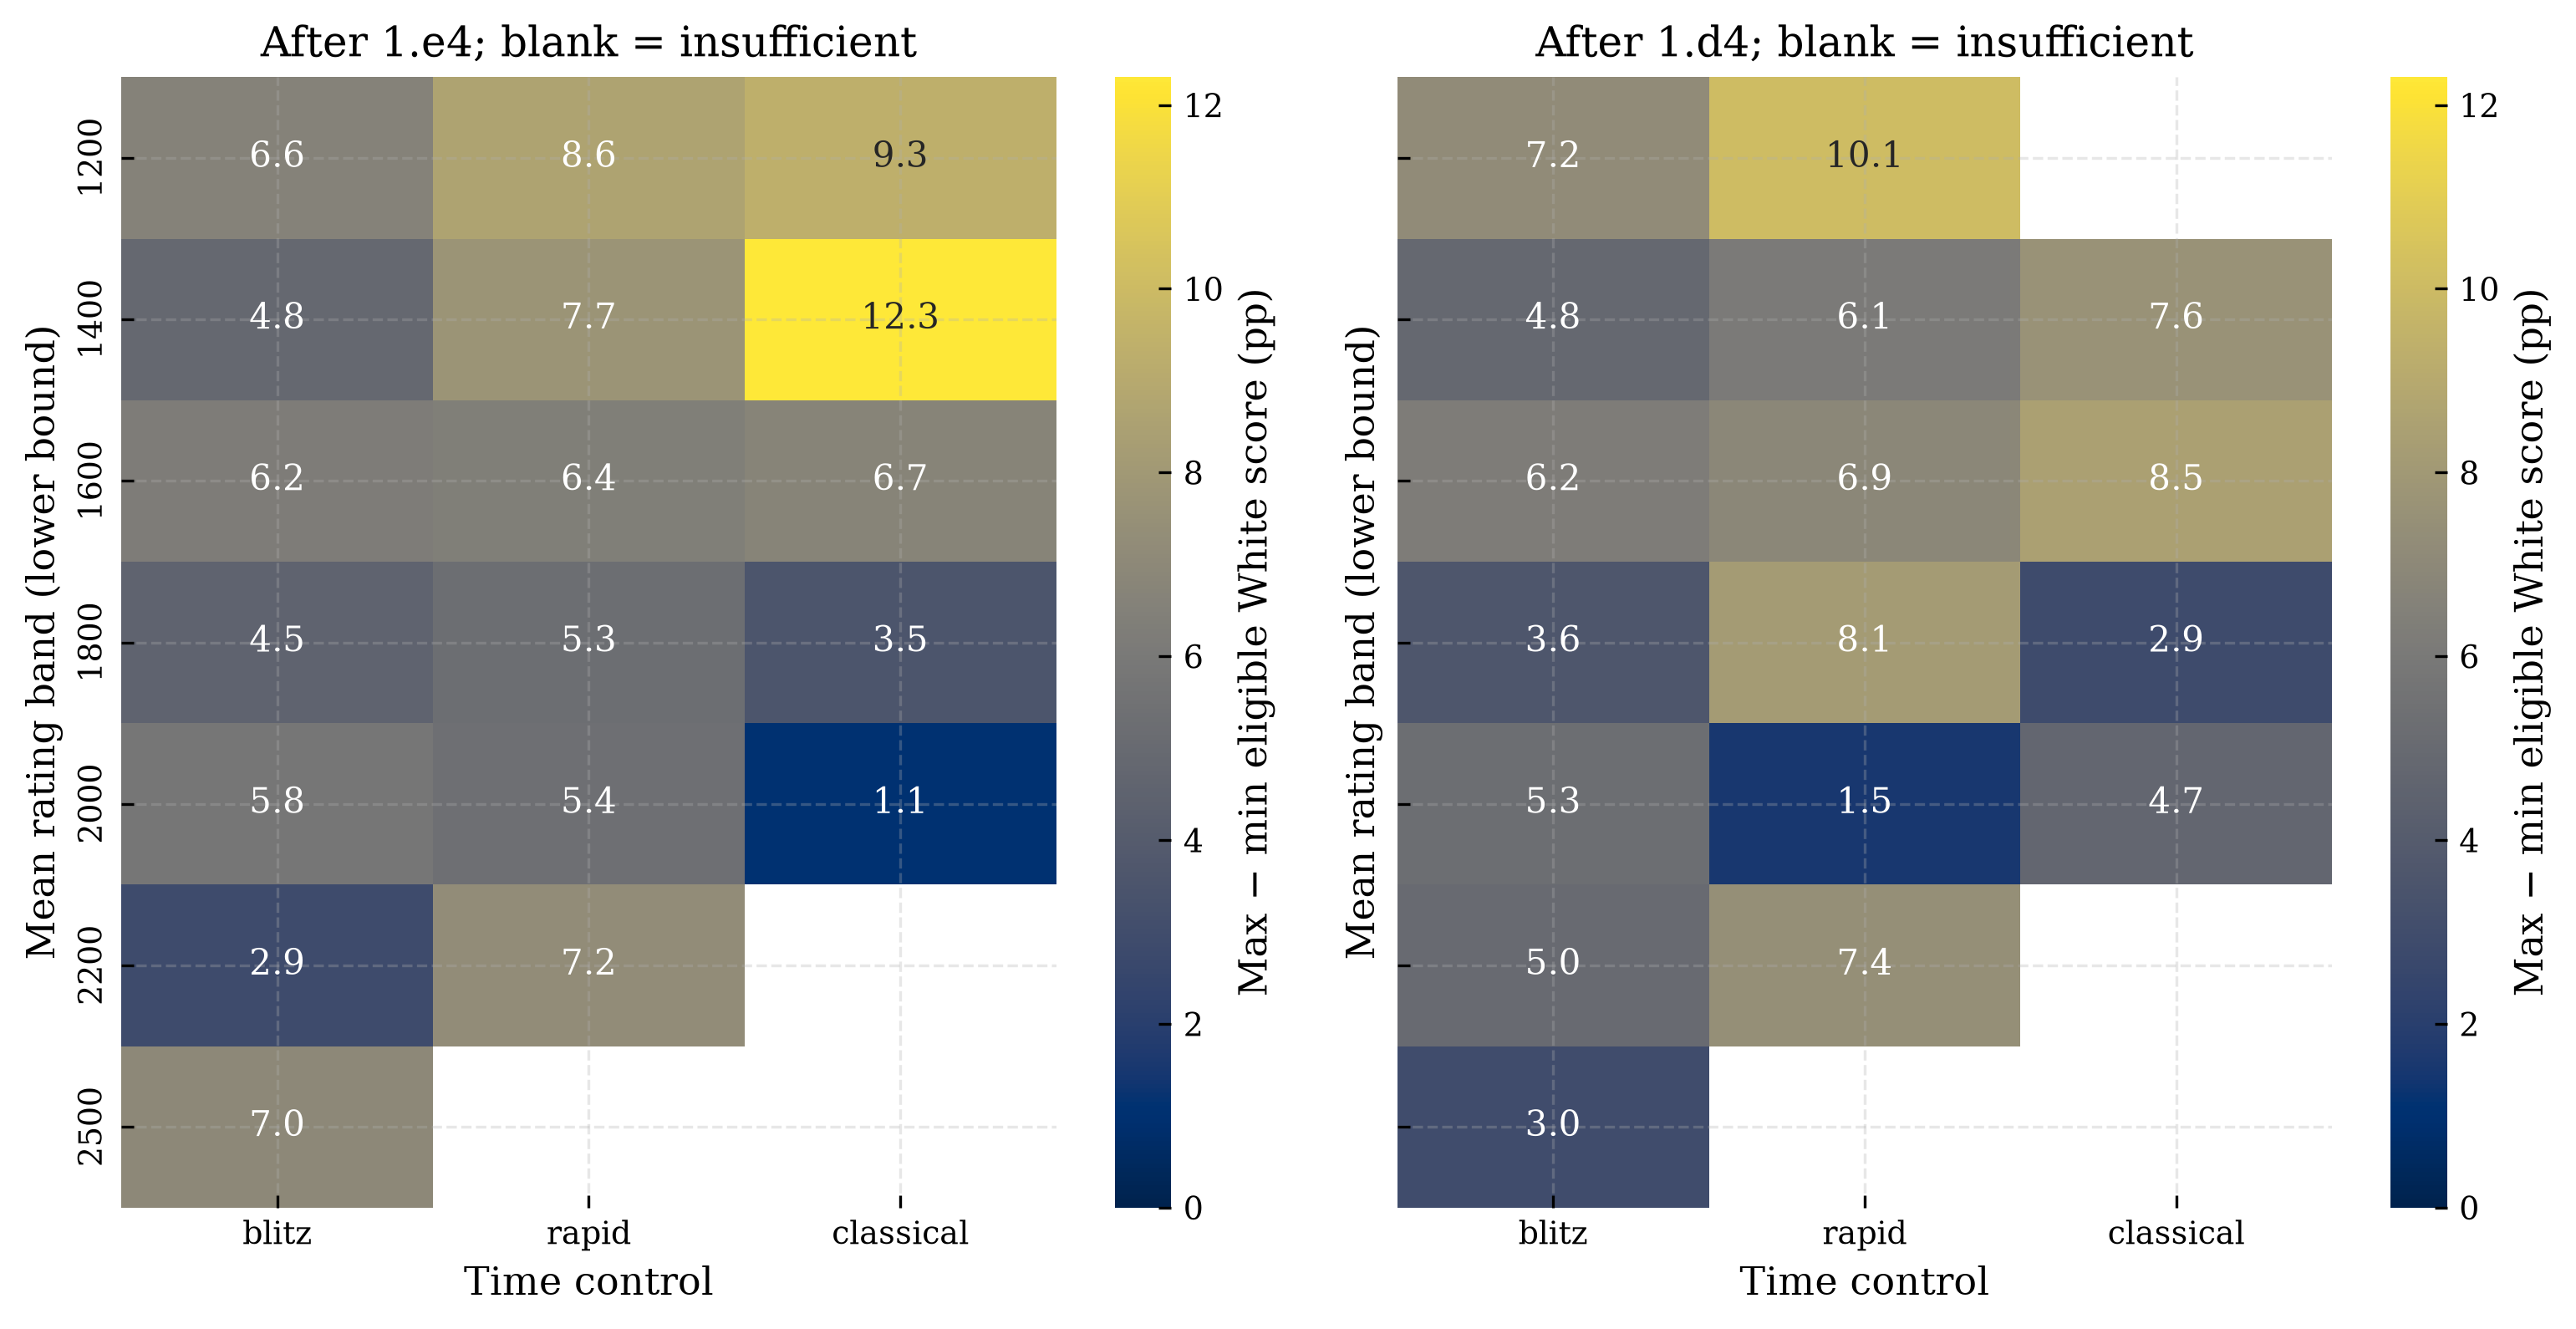

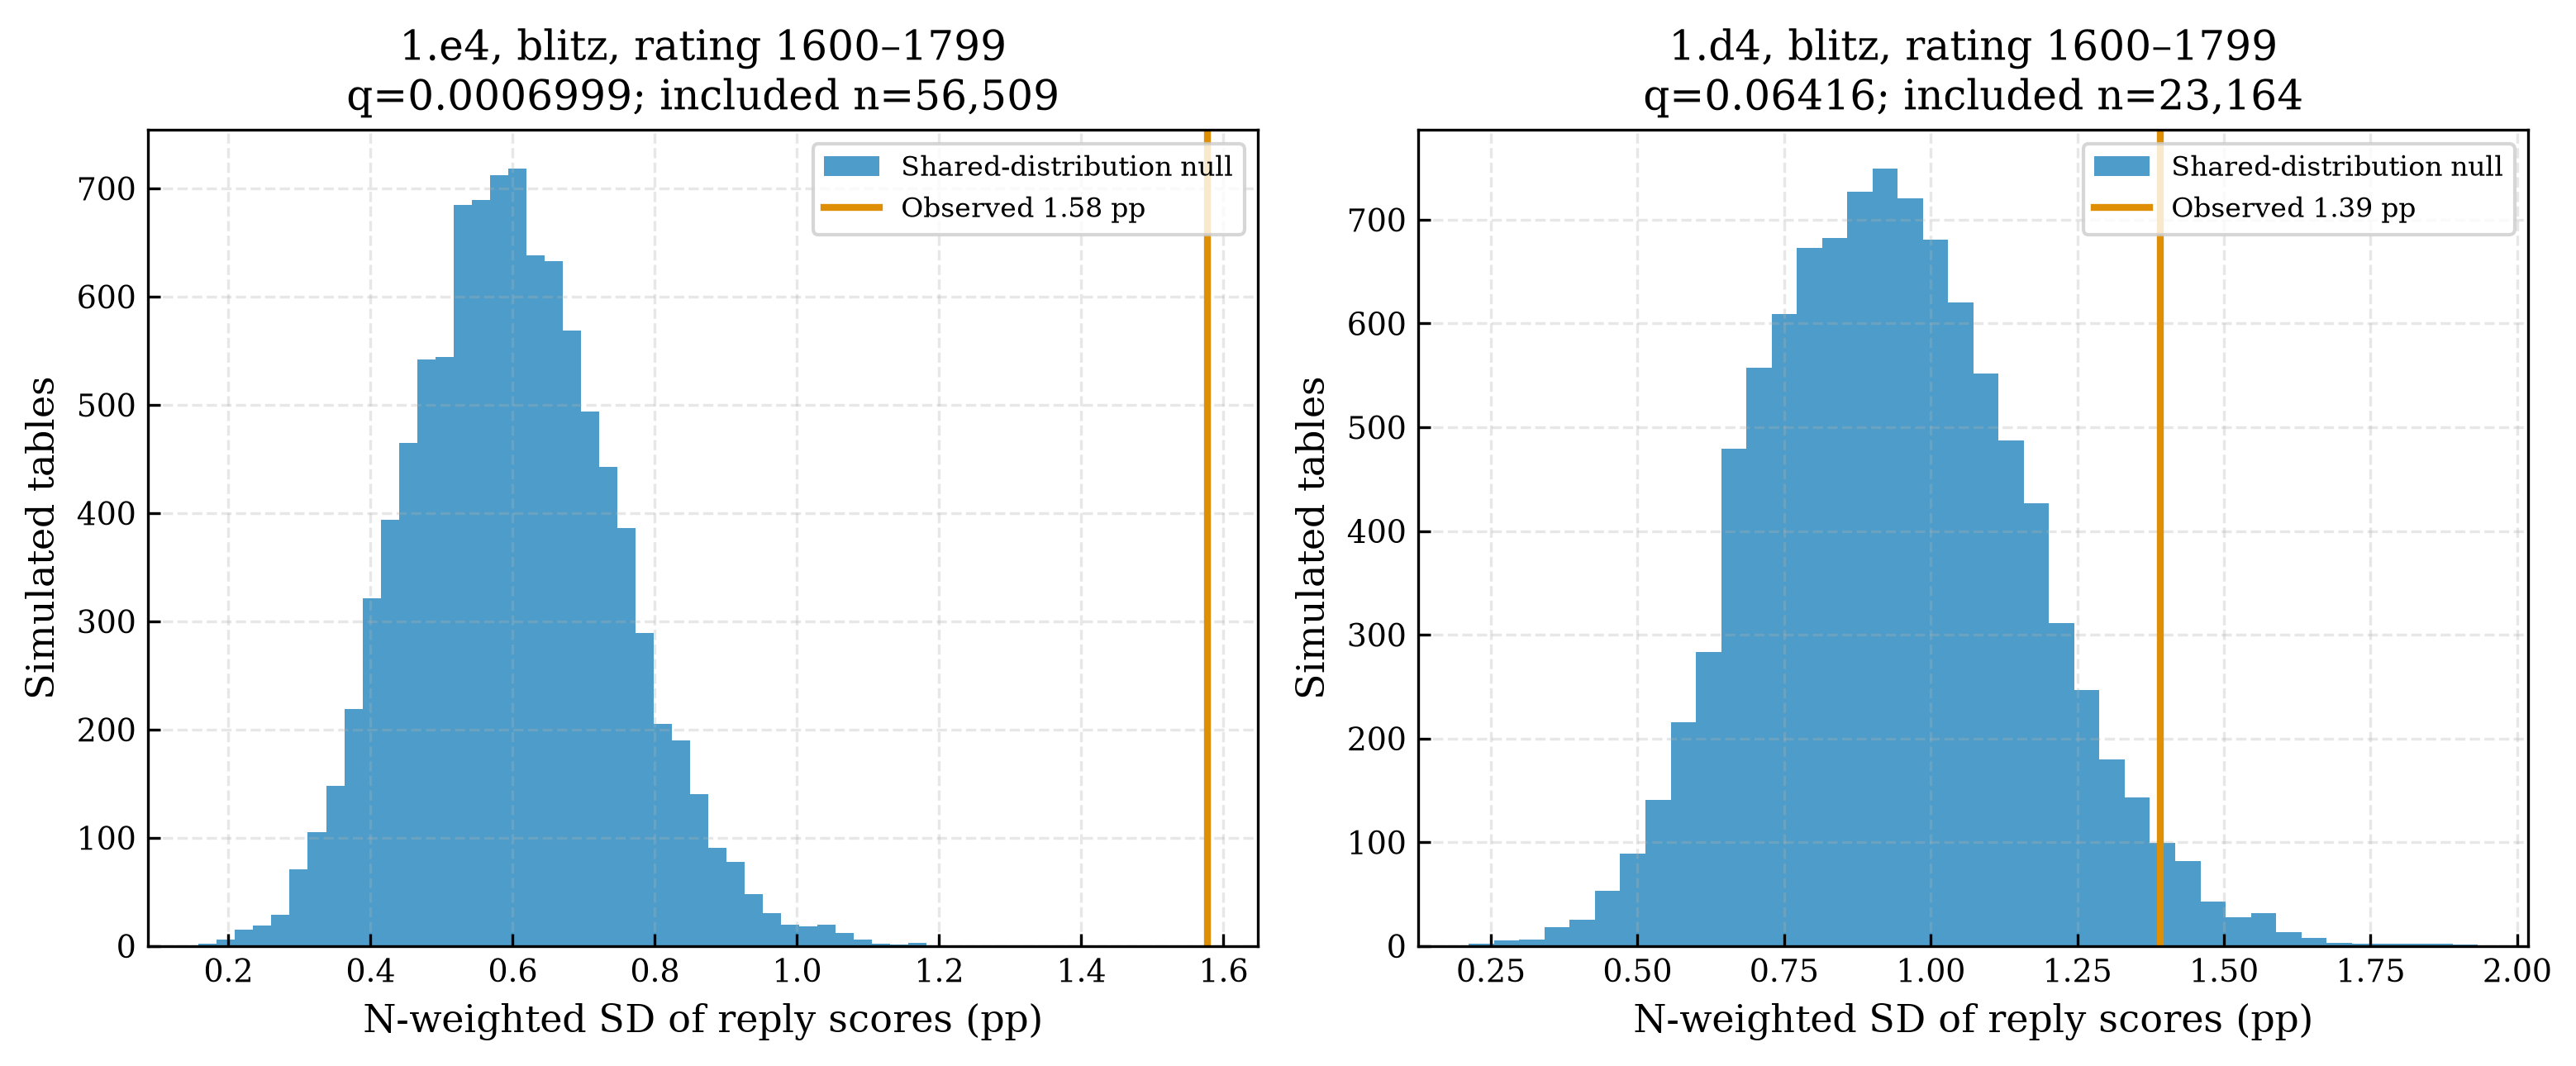

In [8]:
display(h2_display(h2))
display(replies[(replies.band == 1600) & (replies.speed == 'blitz') & replies.tested])
display(Markdown(f"Tested replies cover **{s2['total_selected_coverage']:.1%}** of all e4/d4 games and **{s2['within_band_coverage']:.1%}** within eligible bands. **{s2['score_rejections']}/{s2['tested_cells']}** score-spread tests and **{s2['distribution_rejections']}/{s2['tested_cells']}** full-distribution tests reject after their separate BH corrections. Median range: **{s2['median_range_pp']:.2f} pp**; median excess SD: **{s2['median_excess_sd_pp']:.2f} pp**. Evidence concerns some cells, not all replies in all populations."))
for name in ['fig07_replies_e4', 'fig08_replies_d4', 'fig09_reply_effect_heatmap', 'fig10_h2_null_spread']:
    figure(name)

## 10. Robustness checks

Alternative rating gaps, bands, speed subsets, weights, terminations and game lengths are sensitivity analyses. H2 floors are 100/500/1000; eligible reply sets can change. A 1 pp effect change is a declared descriptive flag. Each H2 sensitivity has its own exploratory BH family; individual H1 sensitivity p-values are unadjusted. Unsigned spread has no effect direction; the detailed table tracks extreme-reply and matched-cell decision changes.

Dyadic sandwich checks account for a player recurring in either color, subtracting unordered-pair covariance to avoid double counting. They still assume disjoint-player games are independent. H2 dyadic checks are limited to the two prespecified representative cells.

In [9]:
robust = table('robustness_results.csv')
display(robust[['hypothesis','scenario','N','score','lo','hi','p_mc','tested_cells','rejected_cells','material_change','significance_changed']])
display(table('h2_sensitivity_cells.csv').head(12))
display(table('source_comparison.csv'))
near_h2 = robust[(robust.hypothesis == 'H2') & (robust.scenario == 'Near equal <=25')].iloc[0]
short = robust[(robust.hypothesis == 'H1') & (robust.scenario == 'At least 40 plies')].iloc[0]
display(Markdown(f"H1 keeps its positive direction, but >=40 plies reduces the score to **{100*short.score:.3f}%**, a material change in magnitude. This selection conditions on a post-opening outcome and changes the population. H2 near-equal ratings leaves only **{int(near_h2.rejected_cells)}/{int(near_h2.tested_cells)}** score rejections. Both less power and reduced confounding may contribute; no stable causal defense ranking follows. Explorer source comparison is unavailable because historical dates/configuration cannot be authenticated."))

,hypothesis,scenario,N,score,lo,hi,p_mc,tested_cells,rejected_cells,material_change,significance_changed
0,H1,Unweighted sample,836070,0.51900,0.51794,0.52005,0.00010,NaN,NaN,False,False
1,H1,Absolute rating difference <= 10,158880,0.51735,0.51475,0.51996,0.00010,NaN,NaN,False,False
2,H1,Absolute rating difference <= 25,327230,0.51819,0.51637,0.52004,0.00010,NaN,NaN,False,False
3,H1,Absolute rating difference <= 50,509899,0.51882,0.51730,0.52030,0.00010,NaN,NaN,False,False
4,H1,Absolute rating difference <= 100,690892,0.51851,0.51720,0.51980,0.00010,NaN,NaN,False,False
5,H1,Exclude time forfeits,665036,0.52149,0.52013,0.52284,0.00010,NaN,NaN,False,False
6,H1,At least 10 plies,827981,0.51700,0.51578,0.51822,0.00010,NaN,NaN,False,False
7,H1,At least 40 plies,688011,0.50769,0.50637,0.50903,0.00010,NaN,NaN,True,False
8,H1,Bands >=1200,730144,0.51727,0.51593,0.51858,0.00010,NaN,NaN,False,False
9,H1,Bands <2200,625850,0.51757,0.51633,0.51881,0.00010,NaN,NaN,False,False


,first,speed,band,total_games,eligible_replies,included_games,coverage,min_n,status,k,...,reject_distribution,range_obs_primary,best_primary,worst_primary,reject_score_primary,range_change_pp,material_change,significance_changed,extreme_reply_changed,scenario
0,d4,blitz,1200,14128,11,13984,0.98981,100,tested,11.00000,...,True,0.07180,d5,f5,True,5.33611,True,False,True,Reply floor 100
1,d4,blitz,1400,19571,11,19395,0.99101,100,tested,11.00000,...,True,0.04819,d5,c5,False,1.26642,True,False,True,Reply floor 100
2,d4,blitz,1600,23480,11,23288,0.99182,100,tested,11.00000,...,False,0.06242,e6,c5,False,0.00000,False,False,False,Reply floor 100
3,d4,blitz,1800,22157,11,22001,0.99296,100,tested,11.00000,...,False,0.03640,e5,c5,False,4.87845,True,False,True,Reply floor 100
4,d4,blitz,2000,13416,11,13329,0.99352,100,tested,11.00000,...,False,0.05271,e6,c5,False,0.33859,False,False,True,Reply floor 100
5,d4,blitz,2200,56502,13,56346,0.99724,100,tested,13.00000,...,True,0.05023,b6,d6,False,0.00000,False,False,False,Reply floor 100
6,d4,blitz,2500,5833,6,5537,0.94925,100,tested,6.00000,...,False,0.02970,e6,d5,False,5.23846,True,False,True,Reply floor 100
7,d4,classical,1400,3176,4,2642,0.83186,100,tested,4.00000,...,False,0.07615,d5,Nf6,True,0.00000,False,True,False,Reply floor 100
8,d4,classical,1600,3236,5,2883,0.89091,100,tested,5.00000,...,True,0.08490,d5,e6,True,9.13858,True,False,True,Reply floor 100
9,d4,classical,1800,2010,3,1644,0.81791,100,tested,3.00000,...,False,0.02864,d5,Nf6,False,0.17555,False,False,True,Reply floor 100


,source,status,comparison,reason,primary_period,explorer_period,rating_alignment
0,Archived Explorer,unverified_legacy,unavailable,Missing original query-period sidecar and resp...,2025-03,unverified,unverified; no numeric comparison made


H1 keeps its positive direction, but >=40 plies reduces the score to **50.769%**, a material change in magnitude. This selection conditions on a post-opening outcome and changes the population. H2 near-equal ratings leaves only **1/28** score rejections. Both less power and reduced confounding may contribute; no stable causal defense ranking follows. Explorer source comparison is unavailable because historical dates/configuration cannot be authenticated.

## 11. Hypothesis decisions

- **H1:** Reject the primary 50% null at .05, under the stated sampling/outcome assumptions. Near-equal ratings and rating standardization support its direction. Secondary tests are adjusted; effect sizes matter separately from p-values.
- **H2:** Evidence of unequal distributions/score spread exists in some specified cells after correction. Other cells are nonsignificant or insufficient, which does not demonstrate equality. Rating restriction and reply eligibility change decisions; interpret opening associations cautiously.

## 12. Scientific discussion

The estimated population scoring difference is modest, despite strong detectability. Rating imbalance does not remove the overall association in the measured adjustments. Pooled time-control scores are similar and rating-band patterns are not monotonic. Draw-rate patterns describe another component of outcomes.

Opening choices are made by systematically different players. Conditioning on broad mean-rating bands is incomplete control for rating imbalance, and neither a spline model nor observational reply comparisons randomizes color or defenses. The near-equal H2 attenuation makes an objective defense ranking particularly unsupported. The 40-ply sensitivity shows why legitimate short games belong in the primary population rather than being silently dropped.

## 13. Limitations

One site and month; selected controls; imperfect strength measurement; unequal sampling rates; dependence between games sharing players; residual tournament/time dependence; model and BH dependence assumptions; sparse high-rated classical groups; endogenous opening preferences; marginal/selected reply intervals; threshold-sensitive H2; game-length selection; unverified Explorer dates/rating semantics; and no validated full ECO join. No full-year, Masters or dashboard claim is made.

The full report documents the pseudo-random sampling assumption, bootstrap/null designs, dyadic formula, spline standardization, complete tables and optional collection plan. Legacy figures concern unverified Explorer data, not this study.

## 14. Final conclusion

The evidence-based short conclusion below is generated from the numerical outputs. Reproduction uses `python -m src.run_analysis`, this notebook, then `python -m pytest -q`. Every figure is also available as PNG and PDF in `figures/`; all numerical results are exported under `results/`.

In [10]:
assert verify_artifacts(ROOT)
display(Markdown((ROOT / 'reports' / 'FINAL_CONCLUSION.md').read_text()))
print('Offline pipeline and artifact checks completed successfully.')

# Final conclusion — White Lies

**1. Is White's advantage statistically detectable?** In the validated sample of 836,070 eligible Lichess games played March 1–31, 2025, the inverse-probability-weighted White score is **51.776%**, with a **95% bootstrap interval of 51.653%–51.899%**. The one-sided draw-preserving Monte Carlo p-value is **9.999e-05**, the resolution limit of 10,000 simulations. We reject the primary 50% null. The raw sample score is 51.900%; its exact conditional p=2.159e-279 is an unweighted cross-check. Among 327,230 games with ratings within 25 Elo, the weighted score is 51.819% (CI 51.637%–52.004%). Equal-rating standardization gives 51.886% (shared-player dyadic CI 51.707%–52.064%; asymptotic p=3.951e-95). The direction survives these adjustments.

**2. Is it practically meaningful?** The primary excess is **1.776 percentage points**, approximately 1.78 additional White points per 100 games relative to equal scoring. It is a modest association, not a guarantee for any individual game. Statistical detectability is stronger than evidence for a universal magnitude: restricting to games lasting at least 40 plies reduces the score to 50.769%.

**3. Does playing strength matter?** Weighted band scores range from 51.370% in band 1800 to 52.336% in band 2200. The pattern is not monotonic. Sparse high-rated classical cells remain inconclusive. These are categories of platform ratings, not controlled comparisons of identical players.

**4. Does time control matter?** Pooled estimates are blitz 51.776% (95% CI 51.637%–51.915%); classical 51.793% (95% CI 51.402%–52.182%); rapid 51.776% (95% CI 51.523%–52.024%). They are very similar; these estimates do not demonstrate a general speed gradient or prove equivalence. Draw rates and rating compositions vary.

**5. Does Black's first reply matter?** With at least 200 games per reply and bands >=1200, **14 of 35 cells** reject score equality and **15** reject full W/D/B equality after separate BH corrections. Tested replies cover 84.3% of all e4/d4 games. Median observed score range is 6.24 pp and median excess SD 1.20 pp. However, the near-equal-rating sensitivity leaves only 1/28 score rejections. Confounding, power, coverage and threshold sensitivity prevent a stable objective-defense ranking.

**6. What does the study demonstrate?** White scores slightly above half in this sampled March population even after measured rating adjustment. Opening replies carry observational outcome associations in some cells. Neither result establishes causation, full-year behavior, or universal chess strategy. Repeated players, model assumptions, unverified Explorer dates and incomplete ECO reconciliation delimit the evidence.


Offline pipeline and artifact checks completed successfully.
